# Analyse et score — segment sans engagement

## Objectif et périmètre

Ce notebook reconstruit le processus de **risk differentiation** : séparation apprentissage/test, contrôles, discrétisation des variables quantitatives, calcul des WoE/IV, régression logistique et comparaison avec un modèle concurrent. Les seuils, regroupements, références et paramètres sont appris sur le train, puis gelés avant toute évaluation sur le test.

Le test est réservé à l'évaluation finale. Un AUC élevé ne démontre ni la calibration des PD, ni la stabilité temporelle, ni la validité métier des variables. La calibration (LRA, MoC) relève d'une étape distincte.

Les variables qualitatives sont exclues du modèle de ce notebook : leur regroupement doit être spécifié et validé séparément.

## Point clé : un `gdt` peut apparaître à plusieurs dates

Dans la base, **l'unité d'observation est le couple (`gdt`, `datdelhis`)** et non le `gdt` seul. Un même client peut donc avoir plusieurs lignes, à des dates différentes. Cela change trois choses :

1. **Contrôle d'unicité** : on vérifie l'unicité de la clé (`gdt`, date), pas celle de `gdt`.
2. **Découpage train/test** : il doit se faire **par client** (groupe `gdt`). Découper ligne par ligne, ou sur une liste d'identifiants avec doublons, peut placer le même client dans le train *et* dans le test : c'est une fuite d'information qui rend l'AUC de test optimiste.
3. **Inférence statistique** : les lignes d'un même client ne sont pas indépendantes. Les erreurs standard et les intervalles de confiance sont donc calculés avec une **correction par grappes (cluster-robust) sur `gdt`**.

## Modifications par rapport à la version initiale

- Prise en compte des `gdt` multi-dates (sections 1, 2, 11, 12, 13).
- Ajout du code de `valider_base` et de la définition de `variables_num`, absents du notebook initial (la section 1 ne contenait que du texte).
- Correction d'un bug de la section 10 : `variables_retenues` contenait des noms en `_bin`, ce qui produisait `SamplingWeight_bin_bin` (`ColumnNotFoundError`).
- Exclusion de `SamplingWeight` et `SelectionProb` : ce sont des variables d'échantillonnage (IV ≈ 5,8 dans la version initiale), pas des prédicteurs.
- Ajout d'une étape d'élimination des variables à partition identique (section 9) : sans elle, des variables redondantes (ex. ρ = 1 en section 5) rendent la matrice singulière.
- Réparation de l'encodage des caractères accentués dans les textes.
- Code découpé en petites cellules (définition de fonction / application / vérification).

## 0. Chargement et paramètres

Les chemin et noms de colonnes sont ceux du notebook initial. `DATE_COL` complète `ID_COL` pour définir la clé d'observation.

Vérifier que `TARGET` est une cible binaire 0/1. Les variables numériques codées comme catégories doivent être listées dans `COLONNES_CATEGORIELLES_NUMERIQUES`. Les colonnes qui ne sont pas des prédicteurs (poids d'échantillonnage, etc.) vont dans `COLONNES_EXCLUES`.

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import statsmodels.api as sm
from scipy.stats import chi2, spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [2]:
CACHE = Path("data/segments/mono_sans_engagement/base_mono_sans_engagement.parquet")

ID_COL = "gdt"            # client
DATE_COL = "datdelhis"    # date d'observation : un gdt peut en avoir plusieurs
TARGET = "ddefaut_ndb"

SEED = 42
TEST_SIZE = 0.20
IV_MIN = 0.02             # seuil de pré-sélection
IV_SUSPECT = 0.50         # IV au-delà duquel une variable est signalée pour examen

COLONNES_CATEGORIELLES_NUMERIQUES: set[str] = set()
# Poids / probabilités d'échantillonnage : ce ne sont pas des prédicteurs
COLONNES_EXCLUES: set[str] = {"SamplingWeight", "SelectionProb"}

In [3]:
base = pl.read_parquet(CACHE)
print(f"Dimensions : {base.shape}")
print("Types :", base.schema)

Dimensions : (78118, 173)
Types : Schema({'datdelhis': Date, 'ddefaut_ndb': Float64, 'gdt': String, 'nb_tiers': Float64, 'code_marche_v2': String, 'type_PM_PP': String, 'has_engagement': Float64, 'nb_crt_distincts': Float64, 'engagement': Float64, 'bilan': Float64, 'horsbilan': Float64, 'nb_AC_distincts': Float64, 'nb_agence_gestion_distincts': Float64, 'nb_produits_distincts': Float64, 'nb_credit_immo': Float64, 'nb_credit_immo__sans_garantie': Float64, 'nb_credit_immo__crelog': Float64, 'nb_credit_immo__hypotheque': Float64, 'nb_credit_immo__autre_OCM': Float64, 'nb_credit_immo__contrat_vie': Float64, 'nb_credit_immo__autre_garantie': Float64, 'engagement_immo': Float64, 'engagement_immo__sans_garantie': Float64, 'engagement_immo__crelog': Float64, 'engagement_immo__hypotheque': Float64, 'engagement_immo__autre_OCM': Float64, 'engagement_immo__contrat_vie': Float64, 'engagement_immo__autre_garantie': Float64, 'nb_credit_MLT': Float64, 'nb_credit_MLT__sans_garantie': Float64, 'nb_cred

## 1. Contrat d'entrée et contrôles bloquants

### 1.1 Structure client / dates

Avant tout contrôle, on mesure combien de dates chaque `gdt` possède et comment la cible se répartit. Ces quatre cellules ne modifient pas la base.

In [4]:
# Nombre de dates et de lignes par client
dates_par_client = base.group_by(ID_COL).agg(
    pl.col(DATE_COL).n_unique().alias("nb_dates"),
    pl.len().alias("nb_lignes"),
)
print(f"Clients distincts : {dates_par_client.height} | lignes : {base.height}")

distribution_dates = (
    dates_par_client.group_by("nb_dates")
    .agg(pl.len().alias("nb_clients"))
    .sort("nb_dates")
)
print(distribution_dates)

Clients distincts : 76452 | lignes : 78118
shape: (3, 2)
┌──────────┬────────────┐
│ nb_dates ┆ nb_clients │
│ ---      ┆ ---        │
│ u32      ┆ u32        │
╞══════════╪════════════╡
│ 1        ┆ 74810      │
│ 2        ┆ 1618       │
│ 3        ┆ 24         │
└──────────┴────────────┘


In [5]:
# La clé d'observation (gdt, date) doit être unique
nb_doublons_cle = base.height - base.select([ID_COL, DATE_COL]).unique().height
print(f"Doublons sur la clé ({ID_COL}, {DATE_COL}) : {nb_doublons_cle}")

Doublons sur la clé (gdt, datdelhis) : 0


In [6]:
# Défauts par date : repère de stabilité temporelle (descriptif)
defaut_par_date = (
    base.group_by(DATE_COL)
    .agg(
        pl.len().alias("nb_lignes"),
        pl.col(TARGET).sum().alias("nb_defauts"),
        pl.col(TARGET).mean().alias("taux_defaut"),
    )
    .sort(DATE_COL)
)
print(defaut_par_date)

shape: (4, 4)
┌────────────┬───────────┬────────────┬─────────────┐
│ datdelhis  ┆ nb_lignes ┆ nb_defauts ┆ taux_defaut │
│ ---        ┆ ---       ┆ ---        ┆ ---         │
│ date       ┆ u32       ┆ f64        ┆ f64         │
╞════════════╪═══════════╪════════════╪═════════════╡
│ 2021-01-01 ┆ 19543     ┆ 108.0      ┆ 0.005526    │
│ 2021-02-01 ┆ 19461     ┆ 94.0       ┆ 0.00483     │
│ 2021-03-01 ┆ 19147     ┆ 84.0       ┆ 0.004387    │
│ 2021-04-01 ┆ 19967     ┆ 163.0      ┆ 0.008163    │
└────────────┴───────────┴────────────┴─────────────┘


In [7]:
# Les défauts sont-ils répétés pour un même client ?
defauts_par_client = base.group_by(ID_COL).agg(
    pl.col(TARGET).sum().alias("nb_defauts_client")
)
print(
    defauts_par_client.filter(pl.col("nb_defauts_client") > 0)
    .group_by("nb_defauts_client").agg(pl.len().alias("nb_clients"))
    .sort("nb_defauts_client")
)

shape: (2, 2)
┌───────────────────┬────────────┐
│ nb_defauts_client ┆ nb_clients │
│ ---               ┆ ---        │
│ f64               ┆ u32        │
╞═══════════════════╪════════════╡
│ 1.0               ┆ 431        │
│ 2.0               ┆ 9          │
└───────────────────┴────────────┘


### 1.3 Rôle de `valider_base`

La fonction vérifie que les colonnes d'identifiant, de date et de cible existent et n'ont pas de valeur manquante, que **la clé (`gdt`, date) est unique**, que la cible est dans `{0, 1}`, et qu'il existe des prédicteurs numériques utilisables.

Une clé dupliquée change l'unité statistique. Une cible invalide ne doit pas être supprimée sans décision explicite. La fonction renvoie uniquement les prédicteurs numériques : identifiant, date, cible, colonnes exclues et variables numériques déclarées catégorielles sont écartés.

In [8]:
def valider_base(
    df: pl.DataFrame,
    id_col: str,
    date_col: str,
    target: str,
    exclues: set[str] = frozenset(),
    categorielles_numeriques: set[str] = frozenset(),
) -> list[str]:
    """Vérifie le contrat d'entrée et renvoie les prédicteurs numériques."""
    for col in (id_col, date_col, target):
        if col not in df.columns:
            raise ValueError(f"Colonne absente : {col!r}")
        if df[col].null_count() > 0:
            raise ValueError(f"Valeurs manquantes dans {col!r} : bloquant.")

    doublons = df.height - df.select([id_col, date_col]).unique().height
    if doublons > 0:
        raise ValueError(
            f"{doublons} doublons sur la clé ({id_col}, {date_col}) : "
            "l'unité d'observation n'est pas unique."
        )

    modalites = set(df[target].unique().to_list())
    if not modalites <= {0, 1}:
        raise ValueError(f"Cible hors de {{0, 1}} : {sorted(modalites, key=str)}")
    if len(modalites) < 2:
        raise ValueError("La cible ne contient qu'une seule modalité.")

    interdites = {id_col, date_col, target} | set(exclues) | set(categorielles_numeriques)
    variables = [
        col for col, dtype in zip(df.columns, df.dtypes)
        if dtype.is_numeric() and col not in interdites
    ]
    if not variables:
        raise ValueError("Aucun prédicteur numérique utilisable.")
    return variables

In [9]:
variables_num = valider_base(
    base, ID_COL, DATE_COL, TARGET,
    exclues=COLONNES_EXCLUES,
    categorielles_numeriques=COLONNES_CATEGORIELLES_NUMERIQUES,
)
print(f"Prédicteurs numériques : {len(variables_num)}")

Prédicteurs numériques : 153


## 2. Séparation apprentissage / test par client

Le découpage se fait **sur les clients** (`gdt` uniques), pas sur les lignes. Tous les enregistrements d'un client, à toutes ses dates, vont dans le même ensemble.

La stratification porte sur un indicateur au niveau client : « le client a au moins un défaut sur l'une de ses dates ». La liste des clients est triée avant le tirage pour que le résultat soit reproductible (l'ordre d'un `group_by` ne l'est pas).

Cette séparation mesure la performance sur un échantillon aléatoire de clients tenu à l'écart. Elle ne remplace pas une validation Out-of-Time. Aucun paramètre appris (seuil, regroupement ou coefficient) ne doit être choisi d'après le test.

In [10]:
# Table client : un indicateur « a eu un défaut » pour stratifier
clients = (
    base.group_by(ID_COL)
    .agg((pl.col(TARGET).max() > 0).cast(pl.Int8).alias("client_en_defaut"))
    .sort(ID_COL)
)
print(f"{clients.height} clients, dont {int(clients['client_en_defaut'].sum())} avec au moins un défaut")

76452 clients, dont 440 avec au moins un défaut


In [11]:
train_ids, test_ids = train_test_split(
    clients[ID_COL].to_list(),
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=clients["client_en_defaut"].to_list(),
)

In [12]:
train = base.join(pl.DataFrame({ID_COL: train_ids}), on=ID_COL, how="semi")
test = base.join(pl.DataFrame({ID_COL: test_ids}), on=ID_COL, how="semi")

In [13]:
# Contrôles bloquants : aucun client commun, aucune ligne perdue
clients_communs = set(train[ID_COL].to_list()) & set(test[ID_COL].to_list())
if clients_communs:
    raise RuntimeError(f"{len(clients_communs)} clients présents dans train ET test.")
if train.height + test.height != base.height:
    raise RuntimeError("Des lignes ont été perdues ou dupliquées lors du découpage.")

for nom, df in (("Train", train), ("Test", test)):
    print(
        f"{nom:5s} | clients={df[ID_COL].n_unique():>6} | lignes={df.height:>6} "
        f"| défauts={int(df[TARGET].sum()):>4} | taux={df[TARGET].mean():.4%}"
    )

Train | clients= 61161 | lignes= 62479 | défauts= 359 | taux=0.5746%
Test  | clients= 15291 | lignes= 15639 | défauts=  90 | taux=0.5755%


## 2. Apprentissage des seuils de discrétisation

Un arbre univarié propose des coupures supervisées par la cible. Apprendre ces coupures sur le test ferait intervenir les réponses du test dans la construction des variables et rendrait l'évaluation optimiste. La fonction ci-dessous n'accepte donc que le train.

### Décomposition de `apprendre_seuils`

1. Exclure les valeurs non finies pour apprendre les coupures ; elles seront conservées dans une classe manquante séparée.
2. Ne lancer l'arbre que si la variable et la cible ont chacune au moins deux valeurs distinctes.
3. Limiter le nombre de feuilles et imposer un effectif minimal par feuille (en nombre de lignes : avec des clients multi-dates, une feuille peut ne représenter que peu de clients).
4. Retourner les seuils ordonnés, sans jamais ajuster d'arbre sur le test.

Ces paramètres sont des choix de départ à justifier, et non une optimisation automatique du modèle final.

In [14]:
def apprendre_seuils(
    df_train: pl.DataFrame,
    variables: list[str],
    target: str,
    max_leaf_nodes: int = 5,
    min_leaf_fraction: float = 0.02,
    random_state: int = 42,
) -> dict[str, list[float]]:
    """Apprend des seuils d'arbre univarié exclusivement sur le train."""
    if not 0 < min_leaf_fraction <= 0.5:
        raise ValueError("min_leaf_fraction doit être compris entre 0 et 0,5.")
    seuils = {}
    for col in variables:
        valeurs = df_train[col].cast(pl.Float64).fill_null(float("nan")).to_numpy()
        cible = df_train[target].to_numpy()
        finies = np.isfinite(valeurs)
        x, y = valeurs[finies], cible[finies]
        if np.unique(x).size < 2 or np.unique(y).size < 2:
            seuils[col] = []
            continue
        min_leaf = max(1, int(np.ceil(min_leaf_fraction * len(y))))
        arbre = DecisionTreeClassifier(
            criterion="gini", max_leaf_nodes=max_leaf_nodes,
            min_samples_leaf=min_leaf, random_state=random_state,
        ).fit(x.reshape(-1, 1), y)
        internes = arbre.tree_.children_left != -1
        seuils[col] = sorted(arbre.tree_.threshold[internes].tolist())
    return seuils

In [15]:
seuils_train = apprendre_seuils(train, variables_num, TARGET, random_state=SEED)
print(f"Variables avec au moins une coupure : {sum(bool(v) for v in seuils_train.values())}")

Variables avec au moins une coupure : 55


## 2.1 Application des coupures gelées

### Décomposition de `appliquer_binning`

Pour les valeurs finies, `searchsorted` affecte le numéro d'intervalle défini par les coupures apprises sur le train. Le code `-1` est réservé aux valeurs manquantes ou non finies ; il constitue une modalité explicite, distincte du premier intervalle.

La même fonction et le même dictionnaire `seuils_train` sont utilisés pour le train et le test. Aucun arbre ni seuil n'est recalculé dans cette étape.

In [16]:
def appliquer_binning(
    df: pl.DataFrame,
    seuils: dict[str, list[float]],
) -> pl.DataFrame:
    """Transforme les prédicteurs selon des seuils déjà appris."""
    expressions = []
    for col, bornes in seuils.items():
        valeurs = df[col].cast(pl.Float64).fill_null(float("nan")).to_numpy()
        classes = np.full(len(valeurs), -1, dtype=np.int64)
        finies = np.isfinite(valeurs)
        classes[finies] = np.searchsorted(
            np.asarray(bornes, dtype=float), valeurs[finies], side="left"
        )
        expressions.append(pl.Series(f"{col}_bin", classes, dtype=pl.Int64))
    return df.with_columns(expressions)

In [17]:
train_binned = appliquer_binning(train, seuils_train)
test_binned = appliquer_binning(test, seuils_train)
print(f"train_binned : {train_binned.shape} | test_binned : {test_binned.shape}")

train_binned : (62479, 326) | test_binned : (15639, 326)


## 8. WoE et IV : estimation sur le train

La convention utilisée est `WoE = ln(part des non-défauts / part des défauts)`. Un WoE positif correspond donc à une classe dont la part parmi les non-défauts dépasse sa part parmi les défauts. L'IV est la somme des `(part_non_défauts - part_défauts) × WoE`.

Un lissage de Jeffreys (`alpha = 0,5`) évite les logarithmes infinis. Le bin manquant `-1` est inclus. Les WoE et IV sont estimés sur le train uniquement ; l'IV sert au tri initial et ne prouve pas un pouvoir prédictif hors échantillon.

### Décomposition de `calculer_woe_iv`

1. Compter les bons et défauts dans chaque bin (`_comptes_par_bin`).
2. Calculer les distributions lissées, puis WoE et contribution à l'IV (`_woe_iv_variable`).
3. Appliquer à toutes les variables et renvoyer le dictionnaire des WoE et le tableau des IV (`calculer_woe_iv`), sans utiliser le test.

In [18]:
def _comptes_par_bin(df_train: pl.DataFrame, col: str, target: str) -> list[dict]:
    """Nombre de bons et de défauts dans chaque bin d'une variable."""
    return (
        df_train.select([col, target]).group_by(col)
        .agg(
            (pl.col(target) == 0).sum().alias("nb_bons"),
            (pl.col(target) == 1).sum().alias("nb_defauts"),
        ).sort(col)
        .to_dicts()
    )

In [19]:
def _woe_iv_variable(
    lignes: list[dict], col: str, alpha: float
) -> tuple[dict[int, float], dict]:
    """WoE par bin et IV pour une variable, à partir des comptes par bin."""
    total_bons = sum(ligne["nb_bons"] for ligne in lignes)
    total_defauts = sum(ligne["nb_defauts"] for ligne in lignes)
    if total_bons == 0 or total_defauts == 0:
        raise ValueError(f"Les deux classes doivent être représentées pour {col!r}.")
    n_bins, mapping, iv = len(lignes), {}, 0.0
    for ligne in lignes:
        p_bons = (ligne["nb_bons"] + alpha) / (total_bons + alpha * n_bins)
        p_defauts = (ligne["nb_defauts"] + alpha) / (total_defauts + alpha * n_bins)
        woe = float(np.log(p_bons / p_defauts))
        iv += (p_bons - p_defauts) * woe
        mapping[int(ligne[col])] = woe
    resume = {
        "variable": col, "IV": float(iv), "nb_classes": n_bins,
        "nb_bons": total_bons, "nb_defauts": total_defauts,
    }
    return mapping, resume

In [20]:
def calculer_woe_iv(
    df_train: pl.DataFrame,
    bin_cols: list[str],
    target: str,
    alpha: float = 0.5,
) -> tuple[dict[str, dict[int, float]], pl.DataFrame]:
    """Calcule WoE par classe et IV par variable sur le train."""
    if alpha <= 0:
        raise ValueError("alpha doit être strictement positif.")
    mappings, lignes_iv = {}, []
    for col in bin_cols:
        lignes = _comptes_par_bin(df_train, col, target)
        mappings[col], resume = _woe_iv_variable(lignes, col, alpha)
        lignes_iv.append(resume)
    return mappings, pl.DataFrame(lignes_iv).sort("IV", descending=True)

In [21]:
bin_cols = [f"{col}_bin" for col in variables_num]
woe_mappings, iv_train = calculer_woe_iv(train_binned, bin_cols, TARGET)
print(iv_train)

shape: (153, 5)
┌───────────────────────────────┬──────────┬────────────┬─────────┬────────────┐
│ variable                      ┆ IV       ┆ nb_classes ┆ nb_bons ┆ nb_defauts │
│ ---                           ┆ ---      ┆ ---        ┆ ---     ┆ ---        │
│ str                           ┆ f64      ┆ i64        ┆ i64     ┆ i64        │
╞═══════════════════════════════╪══════════╪════════════╪═════════╪════════════╡
│ anciennete_jour_sain_M0_bin   ┆ 0.905423 ┆ 6          ┆ 62120   ┆ 359        │
│ MINSOLDE_PAR_bin              ┆ 0.874052 ┆ 5          ┆ 62120   ┆ 359        │
│ CRTAD_AG_SOLDE_T4_bin         ┆ 0.74755  ┆ 5          ┆ 62120   ┆ 359        │
│ CRTAD_AG_NBJDE_BA_bin         ┆ 0.739141 ┆ 5          ┆ 62120   ┆ 359        │
│ CRTAD_AG_SOLDE_T2_bin         ┆ 0.663552 ┆ 5          ┆ 62120   ┆ 359        │
│ …                             ┆ …        ┆ …          ┆ …       ┆ …          │
│ TOTAL_TITRES_PRO_IND_0205_bin ┆ 0.0      ┆ 1          ┆ 62120   ┆ 359        │
│ TOTAL_EPS_

In [22]:
# IV très élevés : à examiner avant toute utilisation (fuite d'information, variable
# d'échantillonnage ou de défaut déguisée, bin quasi vide...)
print(iv_train.filter(pl.col("IV") > IV_SUSPECT))

shape: (15, 5)
┌─────────────────────────────┬──────────┬────────────┬─────────┬────────────┐
│ variable                    ┆ IV       ┆ nb_classes ┆ nb_bons ┆ nb_defauts │
│ ---                         ┆ ---      ┆ ---        ┆ ---     ┆ ---        │
│ str                         ┆ f64      ┆ i64        ┆ i64     ┆ i64        │
╞═════════════════════════════╪══════════╪════════════╪═════════╪════════════╡
│ anciennete_jour_sain_M0_bin ┆ 0.905423 ┆ 6          ┆ 62120   ┆ 359        │
│ MINSOLDE_PAR_bin            ┆ 0.874052 ┆ 5          ┆ 62120   ┆ 359        │
│ CRTAD_AG_SOLDE_T4_bin       ┆ 0.74755  ┆ 5          ┆ 62120   ┆ 359        │
│ CRTAD_AG_NBJDE_BA_bin       ┆ 0.739141 ┆ 5          ┆ 62120   ┆ 359        │
│ CRTAD_AG_SOLDE_T2_bin       ┆ 0.663552 ┆ 5          ┆ 62120   ┆ 359        │
│ …                           ┆ …        ┆ …          ┆ …       ┆ …          │
│ CRTAD_AG_SOLDE_T1_bin       ┆ 0.58472  ┆ 5          ┆ 62120   ┆ 359        │
│ CRTAD_AG_NBJDE_BB_bin       ┆ 0.579

In [23]:
print(iv_train.filter(pl.col("IV") < 0.02))

shape: (87, 5)
┌───────────────────────────────┬──────────┬────────────┬─────────┬────────────┐
│ variable                      ┆ IV       ┆ nb_classes ┆ nb_bons ┆ nb_defauts │
│ ---                           ┆ ---      ┆ ---        ┆ ---     ┆ ---        │
│ str                           ┆ f64      ┆ i64        ┆ i64     ┆ i64        │
╞═══════════════════════════════╪══════════╪════════════╪═════════╪════════════╡
│ CRTAR_IND_0036_bin            ┆ 0.004179 ┆ 2          ┆ 62120   ┆ 359        │
│ nb_crt_distincts_bin          ┆ 0.001524 ┆ 2          ┆ 62120   ┆ 359        │
│ nb_AC_distincts_bin           ┆ 0.000303 ┆ 2          ┆ 62120   ┆ 359        │
│ nb_DAV_bin                    ┆ 0.000303 ┆ 2          ┆ 62120   ┆ 359        │
│ nb_tiers_bin                  ┆ 0.0      ┆ 1          ┆ 62120   ┆ 359        │
│ …                             ┆ …        ┆ …          ┆ …       ┆ …          │
│ TOTAL_TITRES_PRO_IND_0205_bin ┆ 0.0      ┆ 1          ┆ 62120   ┆ 359        │
│ TOTAL_EPS_P

###

In [26]:

import pandas as pd
import numpy as np

TARGET = "ddefaut_ndb"
ALPHA = 0.5

# Conversion en Pandas si train_binned est un DataFrame Polars
df = (
    train_binned.to_pandas()
    if hasattr(train_binned, "to_pandas")
    else train_binned.copy()
)


def calculer_woe_par_classe(df, variable, target=TARGET, alpha=ALPHA):
    tableau = (
        df.groupby(variable, observed=True, dropna=False)[target]
        .agg(effectif="count", defauts="sum")
    )

    tableau["non_defauts"] = tableau["effectif"] - tableau["defauts"]

    # Taux de défaut par classe
    tableau["taux_defaut"] = (
        tableau["defauts"] / tableau["effectif"]
    )

    # WoE avec lissage
    n_defauts = tableau["defauts"].sum()
    n_non_defauts = tableau["non_defauts"].sum()
    n_classes = len(tableau)

    tableau["part_defauts"] = (
        (tableau["defauts"] + alpha)
        / (n_defauts + alpha * n_classes)
    )

    tableau["part_non_defauts"] = (
        (tableau["non_defauts"] + alpha)
        / (n_non_defauts + alpha * n_classes)
    )

    tableau["WoE"] = np.log(
        tableau["part_non_defauts"] / tableau["part_defauts"]
    )

    return tableau.reset_index()


def verifier_monotonie(valeurs):
    valeurs = np.asarray(valeurs, dtype=float)
    valeurs = valeurs[np.isfinite(valeurs)]

    if len(valeurs) < 2:
        return "Classes insuffisantes"

    differences = np.diff(valeurs)

    if np.all(differences > 0):
        return "Strictement croissante"
    elif np.all(differences < 0):
        return "Strictement décroissante"
    elif np.all(differences >= 0):
        return "Croissante (non stricte)"
    elif np.all(differences <= 0):
        return "Décroissante (non stricte)"
    else:
        return "Non monotone"


# Toutes les variables explicatives
variables = [col for col in df.columns if col != TARGET]

resultats_monotonie = []
tables_woe = {}

for variable in variables:
    try:
        tableau = calculer_woe_par_classe(df, variable)

        # Stocker le détail du WoE pour chaque classe
        tables_woe[variable] = tableau

        diagnostic_woe = verifier_monotonie(tableau["WoE"])
        diagnostic_taux = verifier_monotonie(tableau["taux_defaut"])

        resultats_monotonie.append({
            "variable": variable,
            "nb_classes": len(tableau),
            "monotonie_WoE": diagnostic_woe,
            "monotonie_taux_defaut": diagnostic_taux,
            "nb_defauts": tableau["defauts"].sum(),
            "effectif": tableau["effectif"].sum()
        })

    except Exception as e:
        resultats_monotonie.append({
            "variable": variable,
            "nb_classes": np.nan,
            "monotonie_WoE": f"Erreur : {e}",
            "monotonie_taux_defaut": None,
            "nb_defauts": np.nan,
            "effectif": np.nan
        })

# Tableau récapitulatif
resultats_monotonie = pd.DataFrame(resultats_monotonie)

display(
    resultats_monotonie.sort_values(
        "monotonie_WoE"
    ).reset_index(drop=True)
)

,variable,nb_classes,monotonie_WoE,monotonie_taux_defaut,nb_defauts,effectif
0,nb_tiers,1,Classes insuffisantes,Classes insuffisantes,359.0,62479
1,code_marche_v2,1,Classes insuffisantes,Classes insuffisantes,359.0,62479
2,type_PM_PP,1,Classes insuffisantes,Classes insuffisantes,359.0,62479
3,has_engagement,1,Classes insuffisantes,Classes insuffisantes,359.0,62479
4,engagement,1,Classes insuffisantes,Classes insuffisantes,359.0,62479
...,...,...,...,...,...,...
320,nb_AC_distincts_bin,2,Strictement décroissante,Strictement croissante,359.0,62479
321,nb_DAV_bin,2,Strictement décroissante,Strictement croissante,359.0,62479
322,CRTAD_IND_0015_bin,4,Strictement décroissante,Strictement croissante,359.0,62479
323,CRTAR_IND_0036_bin,2,Strictement décroissante,Strictement croissante,359.0,62479


### Fusion progressive

On fusionne itérativement les modalités adjacentes qui ne respectent pas l’un des critères suivants :

écart de risque insuffisant,
rupture de monotonie non justifiée,
effectif trop faible,
instabilité temporelle (volume ou risque).


In [27]:
# Paramètres de fusion progressive
MIN_EFFECTIF = 3
MIN_DEFAUTS = 10
MIN_ECART_PD = 0.001  # 0,1 point de pourcentage
MAX_VARIATION_TEMPORELLE = 0.01  # 1 point de pourcentage

In [39]:

import numpy as np
import pandas as pd

TARGET = "ddefaut_ndb"
DATE = "datdelhis"

MIN_EFFECTIF = 3
MIN_DEFAUTS = 3
MIN_ECART_PD = 0.001          # 0,1 point de pourcentage
MAX_VARIATION_TEMPORELLE = 0.01  # 1 point de pourcentage
ALPHA = 0.5


def fusion_progressive(
    df,
    variable,
    class_order=None,
    target=TARGET,
    date_col=DATE,
    min_effectif=MIN_EFFECTIF,
    min_defauts=MIN_DEFAUTS,
    min_ecart_pd=MIN_ECART_PD,
    max_variation=MAX_VARIATION_TEMPORELLE,
    alpha=ALPHA,
    min_obs_periode=30,
    max_iter=100
):
    """
    Fusionne des classes adjacentes d'une variable ordonnée.

    WoE croissant ou stable : convention
    WoE = log(part_non_defauts / part_defauts).

    La stabilité temporelle est évaluée par année.
    """

    if isinstance(df, pd.DataFrame):
        data = df.copy()
    elif hasattr(df, "to_pandas"):
        data = df.to_pandas()
    else:
        raise TypeError("Le DataFrame doit être de type pandas ou Polars.")


    # Conversion en pandas si nécessaire
    if hasattr(data, "to_pandas"):
        data = data.to_pandas()

    if variable not in data.columns:
        raise ValueError(f"Variable absente : {variable}")

    if target not in data.columns or date_col not in data.columns:
        raise ValueError(f"Il faut les colonnes {target} et {date_col}.")

    data[date_col] = pd.to_datetime(data[date_col], errors="coerce")

    # Déterminer l'ordre des classes
    s = data[variable]

    if class_order is None:
        if isinstance(s.dtype, pd.CategoricalDtype):
            class_order = list(s.cat.categories)
        elif pd.api.types.is_numeric_dtype(s):
            class_order = sorted(s.dropna().unique().tolist())
        else:
            raise ValueError(
                "Pour des classes textuelles, fournissez class_order "
                "explicitement, du plus petit au plus grand."
            )

    # Les valeurs manquantes sont conservées hors des fusions
    niveaux = [
        c for c in class_order
        if data.loc[data[variable].notna(), variable].eq(c).any()
    ]

    if len(niveaux) < 2:
        raise ValueError("Il faut au moins deux classes non manquantes.")

    # Chaque groupe contient les classes originales qui le composent
    groupes = [[c] for c in niveaux]
    historique = []

    def stats_groupe(groupe):
        masque = data[variable].isin(groupe)
        d = data.loc[masque]
        n = len(d)
        defauts = d[target].sum()
        non_defauts = n - defauts
        pd_defaut = defauts / n if n else np.nan

        # WoE avec lissage pour éviter les logarithmes de zéro
        n_def_total = data[target].sum()
        n_non_def_total = len(data) - n_def_total
        k = len(groupes)

        part_def = (defauts + alpha) / (
            n_def_total + alpha * k
        )
        part_non_def = (non_defauts + alpha) / (
            n_non_def_total + alpha * k
        )
        woe = np.log(part_non_def / part_def)

        # Variation annuelle du taux de défaut
        temporel = d.dropna(subset=[date_col]).copy()
        if len(temporel):
            temporel["_annee"] = temporel[date_col].dt.year
            annuels = temporel.groupby("_annee").agg(
                n=(target, "size"),
                defauts=(target, "sum")
            )
            annuels = annuels[annuels["n"] >= min_obs_periode]
            taux_annuels = (
                annuels["defauts"] / annuels["n"]
            )
            variation = (
                taux_annuels.max() - taux_annuels.min()
                if len(taux_annuels) >= 2
                else 0.0
            )
        else:
            variation = 0.0

        return {
            "effectif": n,
            "defauts": defauts,
            "PD": pd_defaut,
            "WoE": woe,
            "variation_temporelle": variation
        }

    def tous_stats():
        return [stats_groupe(g) for g in groupes]

    for iteration in range(max_iter):
        stats = tous_stats()

        # Classes trop petites ou insuffisamment renseignées
        a_fusionner = [
            i for i, st in enumerate(stats)
            if st["effectif"] < min_effectif
            or st["defauts"] < min_defauts
            or st["variation_temporelle"] > max_variation
        ]

        # Écart de risque insuffisant entre classes adjacentes
        paires_proches = []
        for i in range(len(groupes) - 1):
            ecart = abs(stats[i]["PD"] - stats[i + 1]["PD"])
            if ecart < min_ecart_pd:
                paires_proches.append((i, i + 1, ecart))

        # WoE non croissant : détecter les ruptures
        ruptures = []
        for i in range(len(groupes) - 1):
            if stats[i]["WoE"] > stats[i + 1]["WoE"]:
                ruptures.append((i, i + 1))

        if not a_fusionner and not paires_proches and not ruptures:
            break

        # Choisir une paire adjacente à fusionner
        candidats = []

        for i in a_fusionner:
            if i > 0:
                candidats.append((i - 1, i))
            if i < len(groupes) - 1:
                candidats.append((i, i + 1))

        candidats += [(i, j) for i, j, _ in paires_proches]
        candidats += ruptures

        # Éviter les doublons
        candidats = list(set(candidats))

        if not candidats:
            break

        # Priorité à la paire dont les taux de défaut sont les plus proches
        i, j = min(
            candidats,
            key=lambda paire: abs(
                stats[paire[0]]["PD"] - stats[paire[1]]["PD"]
            )
        )

        historique.append({
            "iteration": iteration + 1,
            "classes_fusionnees": (
                groupes[i].copy(), groupes[j].copy()
            ),
            "ecart_PD": abs(stats[i]["PD"] - stats[j]["PD"])
        })

        groupes[i] = groupes[i] + groupes[j]
        del groupes[j]

    # Construire une nouvelle variable avec les classes fusionnées
    mapping = {}
    for numero, groupe in enumerate(groupes, start=1):
        etiquette = " + ".join(map(str, groupe))
        for classe in groupe:
            mapping[classe] = etiquette

    resultat = data.copy()
    resultat[variable] = resultat[variable].map(mapping).fillna(
        resultat[variable]
    )

    # Tableau récapitulatif final
    stats_finaux = []
    for numero, groupe in enumerate(groupes, start=1):
        st = stats_groupe(groupe)
        stats_finaux.append({
            "classe": numero,
            "modalites_initiales": " + ".join(map(str, groupe)),
            **st
        })

    return resultat, pd.DataFrame(stats_finaux), pd.DataFrame(historique)

In [40]:

def fusion_toutes_variables(
    df,
    target=TARGET,
    date_col=DATE,
    ordres_classes=None,
    **kwargs
):
    """
    Applique fusion_progressive à toutes les variables ayant
    au moins deux classes non manquantes.

    Retourne :
      - données avec les variables traitées fusionnées ;
      - diagnostic final par variable ;
      - historiques de fusion ;
      - liste des variables non traitées et leurs motifs.
    """

    # Conversion du DataFrame en pandas
    if isinstance(df, pd.DataFrame):
        resultat_global = df.copy()
    elif hasattr(df, "to_pandas"):
        resultat_global = df.to_pandas()
    else:
        raise TypeError("Le DataFrame doit être de type pandas ou Polars.")

    ordres_classes = ordres_classes or {}

    variables = [
        c for c in resultat_global.columns
        if c not in [target, date_col]
    ]

    diagnostics = []
    historiques = {}
    non_traitees = []

    for variable in variables:
        s = resultat_global[variable]
        valeurs = s.dropna().unique().tolist()

        # 1. Variable constante ou vide
        if len(valeurs) < 2:
            non_traitees.append({
                "variable": variable,
                "motif": (
                    "Aucune valeur exploitable"
                    if len(valeurs) == 0
                    else "Variable constante : une seule classe"
                ),
                "nb_classes_initiales": len(valeurs)
            })
            continue

        # 2. Déterminer l'ordre des classes
        ordre = ordres_classes.get(variable)

        if ordre is None:
            if pd.api.types.is_numeric_dtype(s):
                ordre = sorted(valeurs)
            elif isinstance(s.dtype, pd.CategoricalDtype) and s.cat.ordered:
                ordre = [
                    c for c in s.cat.categories
                    if c in valeurs
                ]
            else:
                non_traitees.append({
                    "variable": variable,
                    "motif": (
                        "Variable catégorielle sans ordre explicite ; "
                        "fournir ordres_classes[variable]"
                    ),
                    "nb_classes_initiales": len(valeurs)
                })
                continue

        # 3. Traiter la variable
        try:
            resultat_var, diagnostic, historique = fusion_progressive(
                resultat_global,
                variable=variable,
                class_order=ordre,
                target=target,
                date_col=date_col,
                **kwargs
            )

            resultat_global[variable] = resultat_var[variable]

            diagnostics.append({
                "variable": variable,
                "nb_classes_initiales": len(valeurs),
                "nb_classes_finales": len(diagnostic),
                "nb_fusions": len(historique),
                "statut": "Traitée"
            })

            historiques[variable] = historique

        except Exception as e:
            non_traitees.append({
                "variable": variable,
                "motif": f"{type(e).__name__} : {e}",
                "nb_classes_initiales": len(valeurs)
            })

    return (
        resultat_global,
        pd.DataFrame(diagnostics),
        historiques,
        pd.DataFrame(non_traitees)
    )

In [42]:
import polars as pl

TARGET = "ddefaut_ndb"
DATE = "datdelhis"

variables = [
    c for c in train_binned.columns
    if c not in [TARGET, DATE]
]

diagnostic_classes = train_binned.select([
    pl.col(c).drop_nulls().n_unique().alias(c)
    for c in variables
])

nb_classes = diagnostic_classes.row(0, named=True)

print("Nombre de variables :", len(variables))
print(
    "Variables avec au moins 2 classes :",
    sum(n >= 2 for n in nb_classes.values())
)

Nombre de variables : 324
Variables avec au moins 2 classes : 172


In [43]:

import numpy as np
import pandas as pd

TARGET = "ddefaut_ndb"
DATE = "datdelhis"

MIN_EFFECTIF = 3
MIN_DEFAUTS = 3
MIN_ECART_PD = 0.001
MAX_VARIATION_TEMPORELLE = 0.01
ALPHA = 0.5
MIN_OBS_PERIODE = 30


def fusion_toutes_variables_rapide(
    df,
    target=TARGET,
    date_col=DATE,
    ordres_classes=None,
    min_effectif=MIN_EFFECTIF,
    min_defauts=MIN_DEFAUTS,
    min_ecart_pd=MIN_ECART_PD,
    max_variation=MAX_VARIATION_TEMPORELLE,
    alpha=ALPHA,
    min_obs_periode=MIN_OBS_PERIODE,
    max_iter=100
):
    # Conversion une seule fois
    if isinstance(df, pd.DataFrame):
        data = df.copy()
    elif hasattr(df, "to_pandas"):
        data = df.to_pandas()
    else:
        raise TypeError("DataFrame pandas ou Polars attendu.")

    if target not in data or date_col not in data:
        raise ValueError(f"Colonnes requises : {target}, {date_col}")

    data[date_col] = pd.to_datetime(data[date_col], errors="coerce")
    data["_annee_fusion"] = data[date_col].dt.year

    ordres_classes = ordres_classes or {}

    variables = [
        c for c in data.columns
        if c not in [target, date_col, "_annee_fusion"]
    ]

    diagnostics = []
    non_traitees = []
    historiques = {}
    resultat = data.copy()

    # Total de défauts et non-défauts pour les WoE
    cible_valide = data[target].dropna()
    total_defauts = cible_valide.sum()
    total_non_defauts = len(cible_valide) - total_defauts

    for numero, variable in enumerate(variables, start=1):
        print(f"[{numero}/{len(variables)}] {variable}", flush=True)

        s = data[variable]
        valeurs = s.dropna().unique().tolist()

        if len(valeurs) < 2:
            non_traitees.append({
                "variable": variable,
                "motif": "Variable constante ou vide",
                "nb_classes": len(valeurs)
            })
            continue

        ordre = ordres_classes.get(variable)

        if ordre is None:
            if pd.api.types.is_numeric_dtype(s):
                ordre = sorted(valeurs)
            elif isinstance(s.dtype, pd.CategoricalDtype) and s.cat.ordered:
                ordre = [v for v in s.cat.categories if v in valeurs]
            else:
                non_traitees.append({
                    "variable": variable,
                    "motif": "Ordre des classes à préciser",
                    "nb_classes": len(valeurs)
                })
                continue

        ordre = [v for v in ordre if s.eq(v).any()]

        if len(ordre) < 2:
            non_traitees.append({
                "variable": variable,
                "motif": "Moins de deux classes dans l'ordre fourni",
                "nb_classes": len(ordre)
            })
            continue

        # Agrégation initiale par classe et année : une seule fois
        d = data[[variable, target, "_annee_fusion"]].dropna(
            subset=[variable, target]
        )

        agg = d.groupby(
            [variable, "_annee_fusion"],
            observed=True,
            dropna=False
        )[target].agg(["size", "sum"])

        # Statistiques de chaque classe originale
        stats_orig = {}
        for classe in ordre:
            try:
                sous = agg.xs(classe, level=0)
                par_annee = {
                    annee: (int(row["size"]), float(row["sum"]))
                    for annee, row in sous.iterrows()
                    if pd.notna(annee)
                }
                n = int(sous["size"].sum())
                defauts = float(sous["sum"].sum())
            except KeyError:
                par_annee = {}
                n = 0
                defauts = 0.0

            stats_orig[classe] = {
                "n": n,
                "d": defauts,
                "annees": par_annee
            }

        groupes = [[c] for c in ordre]
        historique = []

        def stats_groupe(groupe, nb_groupes):
            n = sum(stats_orig[c]["n"] for c in groupe)
            defauts = sum(stats_orig[c]["d"] for c in groupe)
            non_defauts = n - defauts
            pd_defaut = defauts / n if n else np.nan

            part_d = (defauts + alpha) / (
                total_defauts + alpha * nb_groupes
            )
            part_nd = (non_defauts + alpha) / (
                total_non_defauts + alpha * nb_groupes
            )
            woe = np.log(part_nd / part_d)

            # Somme des effectifs et défauts par année
            annuels = {}
            for c in groupe:
                for annee, (n_a, d_a) in stats_orig[c]["annees"].items():
                    if annee not in annuels:
                        annuels[annee] = [0, 0.0]
                    annuels[annee][0] += n_a
                    annuels[annee][1] += d_a

            taux = [
                d_a / n_a
                for n_a, d_a in annuels.values()
                if n_a >= min_obs_periode
            ]

            variation = (
                max(taux) - min(taux) if len(taux) >= 2 else 0.0
            )

            return {
                "effectif": n,
                "defauts": defauts,
                "PD": pd_defaut,
                "WoE": woe,
                "variation_temporelle": variation
            }

        for iteration in range(max_iter):
            stats = [
                stats_groupe(g, len(groupes))
                for g in groupes
            ]

            # Classes ne respectant pas les seuils
            a_fusionner = [
                i for i, st in enumerate(stats)
                if (
                    st["effectif"] < min_effectif
                    or st["defauts"] < min_defauts
                    or st["variation_temporelle"] > max_variation
                )
            ]

            # Classes adjacentes aux risques trop proches
            paires_proches = [
                i for i in range(len(groupes) - 1)
                if abs(stats[i]["PD"] - stats[i + 1]["PD"])
                < min_ecart_pd
            ]

            # WoE croissant ou stable
            ruptures = [
                i for i in range(len(groupes) - 1)
                if stats[i]["WoE"] > stats[i + 1]["WoE"]
            ]

            if not a_fusionner and not paires_proches and not ruptures:
                break

            candidats = set()

            for i in a_fusionner:
                if i > 0:
                    candidats.add(i - 1)
                if i < len(groupes) - 1:
                    candidats.add(i)

            candidats.update(paires_proches)
            candidats.update(ruptures)

            # Conserver au moins deux classes
            candidats = [
                i for i in candidats
                if 0 <= i < len(groupes) - 1
            ]

            if not candidats or len(groupes) <= 2:
                break

            # Fusionner les classes adjacentes dont les PD sont
            # les plus proches parmi les paires candidates
            i = min(
                candidats,
                key=lambda j: abs(stats[j]["PD"] - stats[j + 1]["PD"])
            )

            historique.append({
                "iteration": iteration + 1,
                "classes_fusionnees": (
                    groupes[i].copy(), groupes[i + 1].copy()
                ),
                "ecart_PD": abs(stats[i]["PD"] - stats[i + 1]["PD"])
            })

            groupes[i] = groupes[i] + groupes[i + 1]
            del groupes[i + 1]

        # Mapping final
        mapping = {}
        for k, groupe in enumerate(groupes, start=1):
            etiquette = " + ".join(map(str, groupe))
            for classe in groupe:
                mapping[classe] = etiquette

        resultat[variable] = resultat[variable].map(mapping).where(
            resultat[variable].notna(),
            data[variable]
        )

        stats_finaux = [
            {
                "classe": k,
                "modalites_initiales": " + ".join(map(str, g)),
                **stats_groupe(g, len(groupes))
            }
            for k, g in enumerate(groupes, start=1)
        ]

        diagnostic = pd.DataFrame(stats_finaux)
        historiques[variable] = pd.DataFrame(historique)

        # Vérifier si certains critères restent insatisfaits
        criteres_non_resolus = []

        for st in stats_finaux:
            if st["effectif"] < min_effectif:
                criteres_non_resolus.append("Effectif minimal")
            if st["defauts"] < min_defauts:
                criteres_non_resolus.append("Nombre minimal de défauts")
            if st["variation_temporelle"] > max_variation:
                criteres_non_resolus.append("Stabilité temporelle")

        for j in range(len(stats_finaux) - 1):
            if abs(stats_finaux[j]["PD"] - stats_finaux[j + 1]["PD"]) < min_ecart_pd:
                criteres_non_resolus.append("Écart minimal de PD")
            if stats_finaux[j]["WoE"] > stats_finaux[j + 1]["WoE"]:
                criteres_non_resolus.append("Monotonie WoE")

        diagnostics.append({
            "variable": variable,
            "nb_classes_initiales": len(ordre),
            "nb_classes_finales": len(groupes),
            "nb_fusions": len(historique),
            "statut": (
                "Traitée"
                if not criteres_non_resolus
                else "Traitée, critères non résolus"
            ),
            "criteres_non_resolus": ", ".join(
                sorted(set(criteres_non_resolus))
            )
        })

    resultat = resultat.drop(columns=["_annee_fusion"])

    return (
        resultat,
        pd.DataFrame(diagnostics),
        historiques,
        pd.DataFrame(non_traitees)
    )

In [44]:
(
    train_fusionne,
    diagnostic_global,
    historiques_fusion,
    variables_non_traitees
) = fusion_toutes_variables_rapide(train_binned)

display(diagnostic_global)
display(variables_non_traitees)

[1/324] gdt
[2/324] nb_tiers
[3/324] code_marche_v2
[4/324] type_PM_PP
[5/324] has_engagement
[6/324] nb_crt_distincts
[7/324] engagement
[8/324] bilan
[9/324] horsbilan
[10/324] nb_AC_distincts
[11/324] nb_agence_gestion_distincts
[12/324] nb_produits_distincts
[13/324] nb_credit_immo
[14/324] nb_credit_immo__sans_garantie
[15/324] nb_credit_immo__crelog
[16/324] nb_credit_immo__hypotheque
[17/324] nb_credit_immo__autre_OCM
[18/324] nb_credit_immo__contrat_vie
[19/324] nb_credit_immo__autre_garantie
[20/324] engagement_immo
[21/324] engagement_immo__sans_garantie
[22/324] engagement_immo__crelog
[23/324] engagement_immo__hypotheque
[24/324] engagement_immo__autre_OCM
[25/324] engagement_immo__contrat_vie
[26/324] engagement_immo__autre_garantie
[27/324] nb_credit_MLT
[28/324] nb_credit_MLT__sans_garantie
[29/324] nb_credit_MLT__interfimo
[30/324] nb_credit_MLT__autre_OCM
[31/324] nb_credit_MLT__PGE
[32/324] nb_credit_MLT__autre_garantie
[33/324] engagement_MLT
[34/324] engagement_MLT_

,variable,nb_classes_initiales,nb_classes_finales,nb_fusions,statut,criteres_non_resolus
0,nb_crt_distincts,8,2,6,"Traitée, critères non résolus","Monotonie WoE, Nombre minimal de défauts"
1,nb_AC_distincts,7,2,5,"Traitée, critères non résolus","Monotonie WoE, Nombre minimal de défauts"
2,nb_agence_gestion_distincts,3,2,1,"Traitée, critères non résolus","Monotonie WoE, Nombre minimal de défauts"
3,nb_produits_distincts,2,2,0,"Traitée, critères non résolus",Nombre minimal de défauts
4,nb_DAV,8,2,6,"Traitée, critères non résolus","Monotonie WoE, Nombre minimal de défauts"
...,...,...,...,...,...,...
158,MVTAFF_STABILITE_2T_vs_12M_bin,6,2,4,"Traitée, critères non résolus",Monotonie WoE
159,PART_EPARGNE_DANS_AVOIRS_bin,6,3,3,Traitée,
160,RATIO_LITIGES_vs_AVOIRS_bin,2,2,0,Traitée,
161,RATIO_ECR_bin,6,2,4,"Traitée, critères non résolus",Écart minimal de PD


,variable,motif,nb_classes
0,gdt,Ordre des classes à préciser,61161
1,nb_tiers,Variable constante ou vide,1
2,code_marche_v2,Variable constante ou vide,1
3,type_PM_PP,Variable constante ou vide,1
4,has_engagement,Variable constante ou vide,1
...,...,...,...
156,TOTAL_TITRES_PRO_IND_0205_bin,Variable constante ou vide,1
157,TOTAL_EPS_PRO_IND_0208_bin,Variable constante ou vide,1
158,NB_CCT_PRO_bin,Variable constante ou vide,1
159,TX_UTIL_CCT_PRO_bin,Variable constante ou vide,1


In [45]:
display(
    diagnostic_global[
        diagnostic_global["statut"] == "Traitée, critères non résolus"
    ]
)

,variable,nb_classes_initiales,nb_classes_finales,nb_fusions,statut,criteres_non_resolus
0,nb_crt_distincts,8,2,6,"Traitée, critères non résolus","Monotonie WoE, Nombre minimal de défauts"
1,nb_AC_distincts,7,2,5,"Traitée, critères non résolus","Monotonie WoE, Nombre minimal de défauts"
2,nb_agence_gestion_distincts,3,2,1,"Traitée, critères non résolus","Monotonie WoE, Nombre minimal de défauts"
3,nb_produits_distincts,2,2,0,"Traitée, critères non résolus",Nombre minimal de défauts
4,nb_DAV,8,2,6,"Traitée, critères non résolus","Monotonie WoE, Nombre minimal de défauts"
...,...,...,...,...,...,...
143,CRTAR_IND_0036_bin,2,2,0,"Traitée, critères non résolus",Monotonie WoE
151,NBJDE_RATIO_A_vs_A1_bin,6,2,4,"Traitée, critères non résolus",Monotonie WoE
153,RATIO_NBJDEB_NONAUTO_SUR_NBJDEB_bin,2,2,0,"Traitée, critères non résolus",Monotonie WoE
158,MVTAFF_STABILITE_2T_vs_12M_bin,6,2,4,"Traitée, critères non résolus",Monotonie WoE


In [51]:
decoupage_traites = diagnostic_global[
    diagnostic_global["statut"] == "Traitée"
].copy()

display(decoupage_traites)

print("Nombre de variables traitées :", len(decoupage_traites))

,variable,nb_classes_initiales,nb_classes_finales,nb_fusions,statut,criteres_non_resolus
28,CODACVPRO_modif,58,4,54,Traitée,
62,RATIO3_PRO,98,3,95,Traitée,
92,cod_axe_unite,3,2,1,Traitée,
98,solde_DAV_moyen_bin,5,3,2,Traitée,
99,solde_debiteur_bin,5,2,3,Traitée,
100,solde_crediteur_bin,5,3,2,Traitée,
101,anciennete_jour_sain_M0_bin,6,5,1,Traitée,
102,Dfo_max_Mm1_Mm3_bin,2,2,0,Traitée,
103,Dfo_max_Mm4_Mm6_bin,2,2,0,Traitée,
104,Dfo_max_Mm7_Mm9_bin,2,2,0,Traitée,


Nombre de variables traitées : 57


In [52]:
variables_traitees = decoupage_traites["variable"].tolist()

print("Nombre de variables :", len(variables_traitees))
print(variables_traitees)

Nombre de variables : 57
['CODACVPRO_modif', 'RATIO3_PRO', 'cod_axe_unite', 'solde_DAV_moyen_bin', 'solde_debiteur_bin', 'solde_crediteur_bin', 'anciennete_jour_sain_M0_bin', 'Dfo_max_Mm1_Mm3_bin', 'Dfo_max_Mm4_Mm6_bin', 'Dfo_max_Mm7_Mm9_bin', 'Dfo_max_Mm10_Mm12_bin', 'Dfo_max_Mm13_Mm18_bin', 'Dfo_max_Mm19_Mm24_bin', 'Dfo_max_Mm25_Mm36_bin', 'Dfo_max_Mm37_Mm48_bin', 'NBJ_ARR_SS_max_Mm1_Mm3_bin', 'NBJ_ARR_SS_max_Mm4_Mm6_bin', 'NBJ_ARR_SS_max_Mm7_Mm9_bin', 'NBJ_ARR_SS_max_Mm10_Mm12_bin', 'NBJ_ARR_SS_max_Mm13_Mm18_bin', 'NBJ_ARR_SS_max_Mm19_Mm24_bin', 'NBJ_ARR_SS_max_Mm25_Mm36_bin', 'NBJ_ARR_SS_max_Mm37_Mm48_bin', 'ANCIENNETE_modif_bin', 'AGE_PP_EN_MOIS_bin', 'CODACVPRO_modif_bin', 'CRTAD_IND_0038_bin', 'CRTAD_AG_SOLDE_T_bin', 'CRTAD_AG_SOLDE_T1_bin', 'CRTAD_AG_SOLDE_T2_bin', 'CRTAD_AG_SOLDE_T3_bin', 'CRTAD_AG_SOLDE_T4_bin', 'MINSOLDE_PAR_bin', 'CRTAD_AG_SOLDE_IND_0009_bin', 'CRTAD_AG_NBECR_B_bin', 'NBECR_PAR_bin', 'CRTAD_AG_MVTAFF_IND_0010_bin', 'ENCOURS_PAR_bin', 'CRTAE_AG_SLDEPA_bin', 

In [56]:
decoupage_traites = diagnostic_global[
    diagnostic_global["statut"] == "Traitée"
].copy()

variables_traitees = decoupage_traites["variable"].tolist()

print("Nombre de variables traitées :", len(variables_traitees))
display(decoupage_traites)

Nombre de variables traitées : 57


,variable,nb_classes_initiales,nb_classes_finales,nb_fusions,statut,criteres_non_resolus
28,CODACVPRO_modif,58,4,54,Traitée,
62,RATIO3_PRO,98,3,95,Traitée,
92,cod_axe_unite,3,2,1,Traitée,
98,solde_DAV_moyen_bin,5,3,2,Traitée,
99,solde_debiteur_bin,5,2,3,Traitée,
100,solde_crediteur_bin,5,3,2,Traitée,
101,anciennete_jour_sain_M0_bin,6,5,1,Traitée,
102,Dfo_max_Mm1_Mm3_bin,2,2,0,Traitée,
103,Dfo_max_Mm4_Mm6_bin,2,2,0,Traitée,
104,Dfo_max_Mm7_Mm9_bin,2,2,0,Traitée,


## Base discretisées finale

In [61]:
# Variables dont la fusion a été déclarée terminée
decoupage_traites = diagnostic_global.loc[
    diagnostic_global["statut"].eq("Traitée")
].copy()

variables_traitees = decoupage_traites["variable"].tolist()

print("Nombre de variables traitées :", len(variables_traitees))

Nombre de variables traitées : 57


In [62]:
TARGET = "ddefaut_ndb"

colonnes_a_garder = variables_traitees + [TARGET]

train_scoring = train_fusionne[colonnes_a_garder].copy()

print("Dimensions de la base :", train_scoring.shape)
print("Nombre de variables explicatives :", len(variables_traitees))

display(train_scoring.head())

Dimensions de la base : (62479, 58)
Nombre de variables explicatives : 57


,CODACVPRO_modif,RATIO3_PRO,cod_axe_unite,solde_DAV_moyen_bin,solde_debiteur_bin,solde_crediteur_bin,anciennete_jour_sain_M0_bin,Dfo_max_Mm1_Mm3_bin,Dfo_max_Mm4_Mm6_bin,Dfo_max_Mm7_Mm9_bin,...,SOLDE_PENTE_3T_bin,RATIO_SOLDE_MOYEN_SUR_EPARGNE_bin,RATIO_MOUV_AFF_SUR_EPARGNE_bin,SOLDE_VOLATILITE_5T_bin,SOLDE_VOLATILITE_3T_bin,NBECR_EVOLUTION_A_vs_A1_bin,PART_EPARGNE_DANS_AVOIRS_bin,RATIO_LITIGES_vs_AVOIRS_bin,cod_axe_unite_bin,ddefaut_ndb
0,3300.0 + 3410.0 + 3421.0 + 3430.0 + 3431.0 + 3...,-2.0 + -1.0 + 0.0,1.0,4,4,4,4,0,0,0,...,4,1 + 2 + 3 + 4,0,3,2 + 3,3 + 4,1 + 2 + 3 + 4,0,0,0.0
1,6900.0 + 7000.0 + 7100.0 + 7200.0 + 7300.0 + 7...,-2.0 + -1.0 + 0.0,2.0 + 3.0,4,4,4,4,0,0,0,...,0 + 1 + 2 + 3,1 + 2 + 3 + 4,0,4,2 + 3,3 + 4,1 + 2 + 3 + 4,0,1,0.0
2,6900.0 + 7000.0 + 7100.0 + 7200.0 + 7300.0 + 7...,-2.0 + -1.0 + 0.0,1.0,0 + 1 + 2,4,0 + 1 + 2,4,0,0,0,...,0 + 1 + 2 + 3,1 + 2 + 3 + 4,0,0 + 1 + 2,0 + 1,2,1 + 2 + 3 + 4,0,0,0.0
3,6900.0 + 7000.0 + 7100.0 + 7200.0 + 7300.0 + 7...,-2.0 + -1.0 + 0.0,1.0,4,4,4,4,0,0,0,...,0 + 1 + 2 + 3,1 + 2 + 3 + 4,0,3,2 + 3,3 + 4,1 + 2 + 3 + 4,0,0,0.0
4,1100.0 + 1200.0 + 1300.0 + 2100.0 + 2114.0 + 2...,-2.0 + -1.0 + 0.0,1.0,3,4,0 + 1 + 2,3,0,0,0,...,0 + 1 + 2 + 3,-1,0,0 + 1 + 2,0 + 1,-1 + 0 + 1,0,0,0,0.0


In [63]:
# Vérifier l'absence de doublons dans les noms de colonnes
print("Colonnes dupliquées :", train_scoring.columns.duplicated().sum())

# Vérifier la répartition de la cible
display(train_scoring[TARGET].value_counts(dropna=False))

# Vérifier le nombre de classes par variable
nb_classes = train_scoring[variables_traitees].nunique(dropna=False)

display(
    nb_classes.rename("nombre_classes")
    .sort_values()
    .to_frame()
)

Colonnes dupliquées : 0


ddefaut_ndb
0.0    62120
1.0      359
Name: count, dtype: int64

,nombre_classes
cod_axe_unite,2
solde_debiteur_bin,2
Dfo_max_Mm1_Mm3_bin,2
Dfo_max_Mm19_Mm24_bin,2
Dfo_max_Mm13_Mm18_bin,2
Dfo_max_Mm10_Mm12_bin,2
Dfo_max_Mm7_Mm9_bin,2
Dfo_max_Mm4_Mm6_bin,2
Dfo_max_Mm37_Mm48_bin,2
Dfo_max_Mm25_Mm36_bin,2


## Verification de maximiser raisonnablement l’IV

In [64]:

import numpy as np
import pandas as pd

TARGET = "ddefaut_ndb"
DATE = "datdelhis"
ALPHA = 0.5

# Convertir les DataFrames Polars si nécessaire
def vers_pandas(df):
    return df.to_pandas() if hasattr(df, "to_pandas") else df.copy()

df = vers_pandas(train_fusionne)
df_original = vers_pandas(train_binned)

# Variables dont le traitement est terminé
variables_traitees = diagnostic_global.loc[
    diagnostic_global["statut"].eq("Traitée"), "variable"
].tolist()

def calcul_iv(df, variable, target=TARGET, alpha=ALPHA):
    tab = (
        df.groupby(variable, dropna=False, observed=True)[target]
        .agg(effectif="size", defauts="sum")
        .reset_index()
    )

    tab["non_defauts"] = tab["effectif"] - tab["defauts"]

    k = len(tab)
    total_defauts = tab["defauts"].sum()
    total_non_defauts = tab["non_defauts"].sum()

    tab["part_defauts"] = (
        (tab["defauts"] + alpha)
        / (total_defauts + alpha * k)
    )
    tab["part_non_defauts"] = (
        (tab["non_defauts"] + alpha)
        / (total_non_defauts + alpha * k)
    )

    tab["WoE"] = np.log(
        tab["part_non_defauts"] / tab["part_defauts"]
    )

    tab["IV_classe"] = (
        tab["part_non_defauts"] - tab["part_defauts"]
    ) * tab["WoE"]

    tab["PD"] = tab["defauts"] / tab["effectif"]

    return tab, tab["IV_classe"].sum()


# IV de toutes les variables traitées
resultats_iv = []

for variable in variables_traitees:
    tab, iv = calcul_iv(df, variable)

    resultats_iv.append({
        "variable": variable,
        "nb_classes": len(tab),
        "IV": iv,
        "effectif_min": tab["effectif"].min(),
        "defauts_min": tab["defauts"].min(),
        "classes_sans_defaut": int((tab["defauts"] == 0).sum())
    })

table_iv = (
    pd.DataFrame(resultats_iv)
    .sort_values("IV", ascending=False)
    .reset_index(drop=True)
)

display(table_iv)

,variable,nb_classes,IV,effectif_min,defauts_min,classes_sans_defaut
0,anciennete_jour_sain_M0_bin,5,0.901788,1361,55.0,0
1,MINSOLDE_PAR_bin,5,0.874052,2104,9.0,0
2,CRTAD_AG_SOLDE_T4_bin,5,0.747550,1595,8.0,0
3,CRTAD_AG_SOLDE_T2_bin,4,0.656017,1351,14.0,0
4,CRTAD_AG_SOLDE_T3_bin,5,0.627959,1568,11.0,0
5,ENCOURS_PAR_bin,4,0.615726,2458,20.0,0
6,CRTAE_AG_SLDEPA_bin,4,0.611825,3624,14.0,0
7,CRTAD_AG_SOLDE_T_bin,4,0.601163,11235,15.0,0
8,CRTAD_AG_SOLDE_T1_bin,4,0.575097,5115,24.0,0
9,CRTAD_IND_0038_bin,4,0.541150,4557,22.0,0


In [65]:

def verifier_monotonie(df, variable, ordre_classes=None):
    tab = (
        df.groupby(variable, dropna=False, observed=True)[TARGET]
        .agg(effectif="size", defauts="sum", PD="mean")
        .reset_index()
    )

    # Pour une variable numérique non fusionnée, l'ordre est naturel.
    # Pour les libellés fusionnés, fournir explicitement ordre_classes.
    if ordre_classes is not None:
        rang = {c: i for i, c in enumerate(ordre_classes)}
        tab["_rang"] = tab[variable].map(rang)
        tab = tab.sort_values("_rang")
    elif pd.api.types.is_numeric_dtype(tab[variable]):
        tab = tab.sort_values(variable)
    else:
        print(
            "Attention : fournir l'ordre réel des classes "
            "avant de conclure sur la monotonie."
        )

    pd_values = tab["PD"].to_numpy()
    differences = np.diff(pd_values)

    inversions_croissantes = int((differences < 0).sum())
    inversions_decroissantes = int((differences > 0).sum())

    print("Variable :", variable)
    print("Inversions si PD croissante :", inversions_croissantes)
    print("Inversions si PD décroissante :", inversions_decroissantes)

    display(tab.drop(columns=["_rang"], errors="ignore"))
    return tab

### respecter la monotonie (sauf justification métier)

In [66]:
tab_ratio3, iv_ratio3 = calcul_iv(df, "RATIO3_PRO")
print("IV :", iv_ratio3)
display(tab_ratio3)

IV : 0.0631688464027798


,RATIO3_PRO,effectif,defauts,non_defauts,part_defauts,part_non_defauts,WoE,IV_classe,PD
0,-2.0 + -1.0 + 0.0,62317,350.0,61967.0,0.972261,0.997521,0.025649,0.000648,0.005616
1,-72.0 + -66.0 + -63.0 + -62.0 + -59.0 + -56.0 ...,97,4.0,93.0,0.012483,0.001505,-2.115471,0.023223,0.041237
2,-876021.0 + -27410.0 + -3810.0 + -3202.0 + -27...,65,5.0,60.0,0.015257,0.000974,-2.751460,0.039298,0.076923


## Verification de la stabilité temporelle

In [67]:

# Contrôler d'abord l'alignement des deux bases
assert len(df) == len(df_original), (
    "Les bases n'ont pas le même nombre de lignes."
)

assert df[TARGET].reset_index(drop=True).equals(
    df_original[TARGET].reset_index(drop=True)
), "Les lignes ne semblent pas alignées sur la cible."

df_temporel = df.copy()
df_temporel[DATE] = pd.to_datetime(
    df_original[DATE].reset_index(drop=True),
    errors="coerce"
)
df_temporel["_annee"] = df_temporel[DATE].dt.year

def stabilite_temporelle(df, variable, min_obs=30):
    tab = (
        df.dropna(subset=["_annee"])
        .groupby([variable, "_annee"], dropna=False, observed=True)[TARGET]
        .agg(effectif="size", defauts="sum", PD="mean")
        .reset_index()
    )

    tab = tab[tab["effectif"] >= min_obs].copy()

    synthese = (
        tab.groupby(variable, dropna=False)["PD"]
        .agg(PD_min="min", PD_max="max", PD_moyenne="mean")
        .reset_index()
    )

    synthese["amplitude_PD"] = (
        synthese["PD_max"] - synthese["PD_min"]
    )

    display(tab.sort_values([variable, "_annee"]))
    display(synthese)

    return tab, synthese

detail_temps, synthese_temps = stabilite_temporelle(
    df_temporel, "RATIO3_PRO"
)

,RATIO3_PRO,_annee,effectif,defauts,PD
0,-2.0 + -1.0 + 0.0,2021,62317,350.0,0.005616
1,-72.0 + -66.0 + -63.0 + -62.0 + -59.0 + -56.0 ...,2021,97,4.0,0.041237
2,-876021.0 + -27410.0 + -3810.0 + -3202.0 + -27...,2021,65,5.0,0.076923


,RATIO3_PRO,PD_min,PD_max,PD_moyenne,amplitude_PD
0,-2.0 + -1.0 + 0.0,0.005616,0.005616,0.005616,0.0
1,-72.0 + -66.0 + -63.0 + -62.0 + -59.0 + -56.0 ...,0.041237,0.041237,0.041237,0.0
2,-876021.0 + -27410.0 + -3810.0 + -3202.0 + -27...,0.076923,0.076923,0.076923,0.0


### Suite

In [138]:
iv_train = iv_train.filter(pl.col("IV") >= 0.02)
variables_candidates = (
    iv_train
    .filter(
        (pl.col("IV") >= 0.02)
        & (pl.col("IV") < 0.5)
    )
    .sort("IV", descending=True)
)

print(variables_candidates)

shape: (45, 5)
┌──────────────────────────────┬──────────┬────────────┬─────────┬────────────┐
│ variable                     ┆ IV       ┆ nb_classes ┆ nb_bons ┆ nb_defauts │
│ ---                          ┆ ---      ┆ ---        ┆ ---     ┆ ---        │
│ str                          ┆ f64      ┆ i64        ┆ i64     ┆ i64        │
╞══════════════════════════════╪══════════╪════════════╪═════════╪════════════╡
│ NBJ_ARR_SS_max_Mm25_Mm36_bin ┆ 0.398566 ┆ 4          ┆ 62120   ┆ 359        │
│ CRTAD_IND_0015_bin           ┆ 0.371939 ┆ 4          ┆ 62120   ┆ 359        │
│ NBJDE_RATIO_A_vs_A1_bin      ┆ 0.368871 ┆ 6          ┆ 62120   ┆ 359        │
│ NBJ_ARR_SS_max_Mm13_Mm18_bin ┆ 0.364818 ┆ 3          ┆ 62120   ┆ 359        │
│ CRTAD_AG_NBJDE_BC_bin        ┆ 0.362493 ┆ 5          ┆ 62120   ┆ 359        │
│ …                            ┆ …        ┆ …          ┆ …       ┆ …          │
│ Dfo_max_Mm10_Mm12_bin        ┆ 0.027225 ┆ 2          ┆ 62120   ┆ 359        │
│ Dfo_max_Mm13_Mm18_bin  

A cet niveau, on se concentre principalement sur les variables comprrises entre 0,02 et 0,5.

In [140]:
top_15 = variables_candidates
print(top_15)

shape: (45, 5)
┌──────────────────────────────┬──────────┬────────────┬─────────┬────────────┐
│ variable                     ┆ IV       ┆ nb_classes ┆ nb_bons ┆ nb_defauts │
│ ---                          ┆ ---      ┆ ---        ┆ ---     ┆ ---        │
│ str                          ┆ f64      ┆ i64        ┆ i64     ┆ i64        │
╞══════════════════════════════╪══════════╪════════════╪═════════╪════════════╡
│ NBJ_ARR_SS_max_Mm25_Mm36_bin ┆ 0.398566 ┆ 4          ┆ 62120   ┆ 359        │
│ CRTAD_IND_0015_bin           ┆ 0.371939 ┆ 4          ┆ 62120   ┆ 359        │
│ NBJDE_RATIO_A_vs_A1_bin      ┆ 0.368871 ┆ 6          ┆ 62120   ┆ 359        │
│ NBJ_ARR_SS_max_Mm13_Mm18_bin ┆ 0.364818 ┆ 3          ┆ 62120   ┆ 359        │
│ CRTAD_AG_NBJDE_BC_bin        ┆ 0.362493 ┆ 5          ┆ 62120   ┆ 359        │
│ …                            ┆ …        ┆ …          ┆ …       ┆ …          │
│ Dfo_max_Mm10_Mm12_bin        ┆ 0.027225 ┆ 2          ┆ 62120   ┆ 359        │
│ Dfo_max_Mm13_Mm18_bin  

Variance expliquée par composante :
[0.2037 0.103  0.0862 0.0758 0.068  0.0667 0.0664 0.066  0.0621 0.0534
 0.0485 0.0443 0.033  0.0159 0.0073]
Variance cumulée des 2 premières composantes : 30.67 %


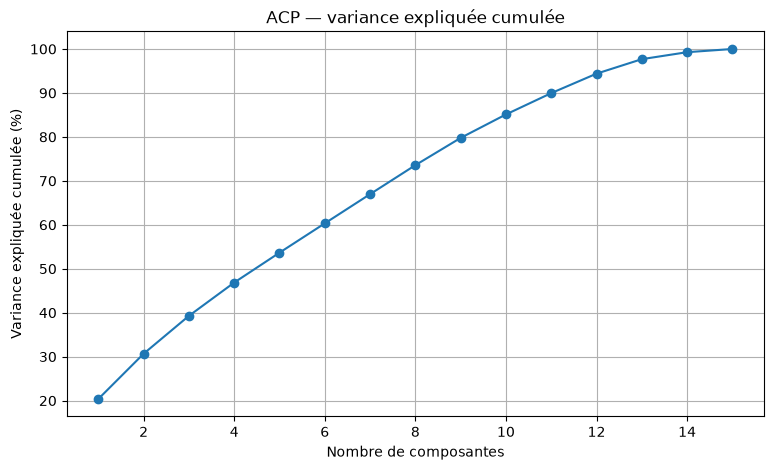

In [141]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Récupérer les 15 variables candidates
variables_bin = (
    variables_candidates
    .head(15)
    .get_column("variable")
    .to_list()
)

variables_originales = [
    col.removesuffix("_bin")
    for col in variables_bin
]

# 2. Construire la matrice sur le train uniquement
X = train.select(variables_originales).to_pandas()

# 3. Traiter les valeurs infinies et manquantes
X = X.replace([np.inf, -np.inf], np.nan)

# Pour une première exploration :
# imputation par la médiane calculée sur le train
X = X.fillna(X.median())

# 4. Retirer les variables constantes
X = X.loc[:, X.nunique() > 1]

# 5. Standardiser
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 6. Calculer l'ACP
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# 7. Variance expliquée
variance = pca.explained_variance_ratio_

print("Variance expliquée par composante :")
print(np.round(variance, 4))

print(
    "Variance cumulée des 2 premières composantes :",
    round(variance[:2].sum() * 100, 2),
    "%"
)

# 8. Scree plot
plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(variance) + 1),
    np.cumsum(variance) * 100,
    marker="o"
)
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée (%)")
plt.title("ACP — variance expliquée cumulée")
plt.grid(True)
plt.show()

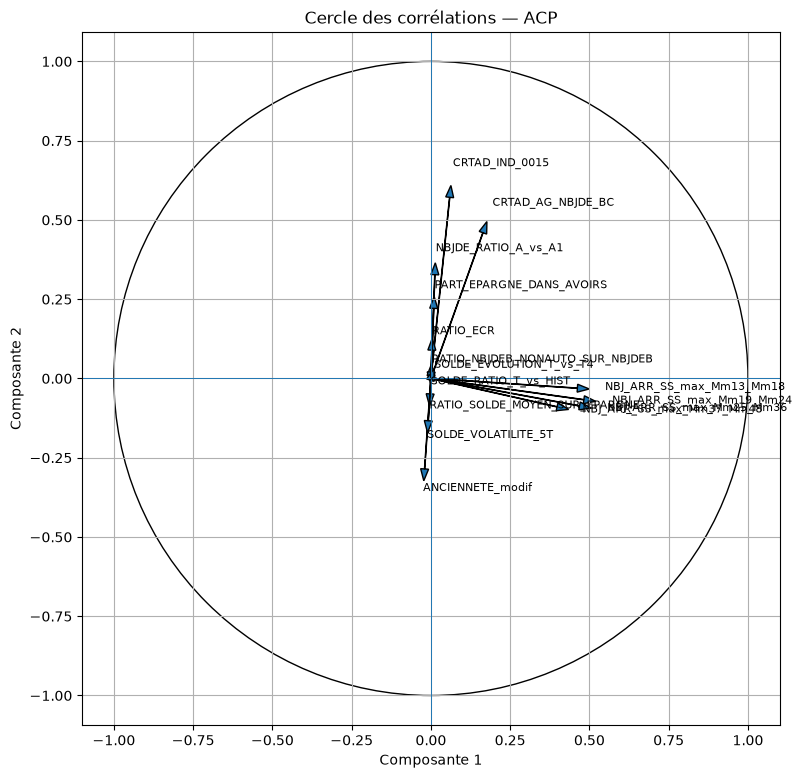

In [142]:
# Coordonnées des variables sur les deux premières composantes
loadings = pca.components_.T[:, :2]

plt.figure(figsize=(9, 9))

for i, variable in enumerate(X.columns):
    plt.arrow(
        0, 0,
        loadings[i, 0],
        loadings[i, 1],
        head_width=0.025,
        length_includes_head=True
    )
    plt.text(
        loadings[i, 0] * 1.10,
        loadings[i, 1] * 1.10,
        variable,
        fontsize=8
    )

cercle = plt.Circle((0, 0), 1, fill=False)
plt.gca().add_patch(cercle)
plt.axhline(0, linewidth=0.7)
plt.axvline(0, linewidth=0.7)
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.xlabel("Composante 1")
plt.ylabel("Composante 2")
plt.title("Cercle des corrélations — ACP")
plt.axis("equal")
plt.grid(True)
plt.show()

## 9. Pré-sélection des variables

Le seuil `IV_MIN` est fixé avant de consulter le test et reprend le repère usuel de 0,02 comme seuil d'information faible. Ce repère reste indicatif : il ne remplace ni l'analyse métier, ni l'examen de la stabilité, de la redondance et de la disponibilité des variables.

Les variables qui passent ce filtre forment une liste de travail, exprimée **par nom de variable d'origine** (sans suffixe `_bin`, qui est ajouté en section 10). Si aucune variable ne le passe, le notebook s'arrête au lieu de construire artificiellement un modèle.

In [ ]:
variables_candidates = (
    iv_train
    .filter(
        (pl.col("IV") >= 0.02)
        & (pl.col("IV") < 0.5)
    )
    .sort("IV", descending=True)
)

print(variables_candidates)

shape: (53, 5)
┌──────────────────────────────┬──────────┬────────────┬─────────┬────────────┐
│ variable                     ┆ IV       ┆ nb_classes ┆ nb_bons ┆ nb_defauts │
│ ---                          ┆ ---      ┆ ---        ┆ ---     ┆ ---        │
│ str                          ┆ f64      ┆ i64        ┆ i64     ┆ i64        │
╞══════════════════════════════╪══════════╪════════════╪═════════╪════════════╡
│ NBJ_ARR_SS_max_Mm25_Mm36_bin ┆ 0.398566 ┆ 4          ┆ 62120   ┆ 359        │
│ CRTAD_IND_0015_bin           ┆ 0.371939 ┆ 4          ┆ 62120   ┆ 359        │
│ NBJDE_RATIO_A_vs_A1_bin      ┆ 0.368871 ┆ 6          ┆ 62120   ┆ 359        │
│ NBJ_ARR_SS_max_Mm13_Mm18_bin ┆ 0.364818 ┆ 3          ┆ 62120   ┆ 359        │
│ CRTAD_AG_NBJDE_BC_bin        ┆ 0.362493 ┆ 5          ┆ 62120   ┆ 359        │
│ …                            ┆ …        ┆ …          ┆ …       ┆ …          │
│ Dfo_max_Mm13_Mm18_bin        ┆ 0.027225 ┆ 2          ┆ 62120   ┆ 359        │
│ Dfo_max_Mm19_Mm24_bin  

In [143]:
# Liste des variables à supprimer
variables_a_supprimer = [
    "NBJ_ARR_SS_max_Mm25_Mm36_bin",
    "NBJ_ARR_SS_max_Mm13_Mm18_bin",
    "AGE_PM_EN_MOIS_bin",
    "AGE_PM_EN_MOIS_bin",
    "LISTE_CODACVPRO_modif_bin",
    "LISTE_CODNAF2_bin",
    "LISTE_CODETAJUR_bin",
    "RATIO_LITIGES_vs_CA_bin",
    "MVTAFF_STABILITE_2T_vs_12M_bin",
    "CODITDBDF_PRO_bin",
    "CRTOC_TOK_0010_bin",
   "flux_pro_bin",                  
   "CODNAF2_bin"     
    
]

variables_candidates = (
    iv_train
    .filter(
        (pl.col("IV") >= 0.02)
        & (pl.col("IV") < 0.5)
        & (~pl.col("variable").is_in(variables_a_supprimer))
    )
    .sort("IV", descending=True)
)

print(variables_candidates)

shape: (43, 5)
┌─────────────────────────────────┬──────────┬────────────┬─────────┬────────────┐
│ variable                        ┆ IV       ┆ nb_classes ┆ nb_bons ┆ nb_defauts │
│ ---                             ┆ ---      ┆ ---        ┆ ---     ┆ ---        │
│ str                             ┆ f64      ┆ i64        ┆ i64     ┆ i64        │
╞═════════════════════════════════╪══════════╪════════════╪═════════╪════════════╡
│ CRTAD_IND_0015_bin              ┆ 0.371939 ┆ 4          ┆ 62120   ┆ 359        │
│ NBJDE_RATIO_A_vs_A1_bin         ┆ 0.368871 ┆ 6          ┆ 62120   ┆ 359        │
│ CRTAD_AG_NBJDE_BC_bin           ┆ 0.362493 ┆ 5          ┆ 62120   ┆ 359        │
│ ANCIENNETE_modif_bin            ┆ 0.356672 ┆ 5          ┆ 62120   ┆ 359        │
│ RATIO_SOLDE_MOYEN_SUR_EPARGNE_… ┆ 0.353347 ┆ 6          ┆ 62120   ┆ 359        │
│ …                               ┆ …        ┆ …          ┆ …       ┆ …          │
│ Dfo_max_Mm10_Mm12_bin           ┆ 0.027225 ┆ 2          ┆ 62120   ┆ 35

In [144]:
top_10 = variables_candidates.head(10)
print(top_10)

shape: (10, 5)
┌─────────────────────────────────┬──────────┬────────────┬─────────┬────────────┐
│ variable                        ┆ IV       ┆ nb_classes ┆ nb_bons ┆ nb_defauts │
│ ---                             ┆ ---      ┆ ---        ┆ ---     ┆ ---        │
│ str                             ┆ f64      ┆ i64        ┆ i64     ┆ i64        │
╞═════════════════════════════════╪══════════╪════════════╪═════════╪════════════╡
│ CRTAD_IND_0015_bin              ┆ 0.371939 ┆ 4          ┆ 62120   ┆ 359        │
│ NBJDE_RATIO_A_vs_A1_bin         ┆ 0.368871 ┆ 6          ┆ 62120   ┆ 359        │
│ CRTAD_AG_NBJDE_BC_bin           ┆ 0.362493 ┆ 5          ┆ 62120   ┆ 359        │
│ ANCIENNETE_modif_bin            ┆ 0.356672 ┆ 5          ┆ 62120   ┆ 359        │
│ RATIO_SOLDE_MOYEN_SUR_EPARGNE_… ┆ 0.353347 ┆ 6          ┆ 62120   ┆ 359        │
│ RATIO_NBJDEB_NONAUTO_SUR_NBJDE… ┆ 0.342938 ┆ 2          ┆ 62120   ┆ 359        │
│ NBJ_ARR_SS_max_Mm19_Mm24_bin    ┆ 0.340181 ┆ 3          ┆ 62120   ┆ 35

CRTAD_IND_0015_bin : Nombre de Jours Débiteurs Mensuel : Nombre de jours où le compte a été en position débitrice durant le mois.
NBJDE_RATIO_A_vs_A1_bin: Ratio Annuel des Jours Débiteurs : Rapport entre le nombre de jours débiteurs des 3 derniers mois et celui de la même période un an avant.
CRTAD_AG_NBJDE_BC_bin :Total Jours Débiteurs (3 mois, Année A-1) : Somme des jours débiteurs sur la même période de 3 mois, l'année précédente.
ANCIENNETE_modif_bin :Ancienneté de la relation client en mois.
RATIO_SOLDE_MOYEN_SUR_EPARGNE:Ratio Solde Courant / Épargne : Taux d'utilisation de l'épargne par le solde des comptes courants. Un ratio élevé peut indiquer une tension de trésorerie.
RATIO_NBJDEB_NONAUTO_SUR_NBJDE: Ratio Jours Débiteurs Non Autorisés : Part des jours en découvert non autorisé parmi tous les jours débiteurs.
NBJ_ARR_SS_max_Mm19_Mm24_bin: 
SOLDE_VOLATILITE_5T_bin: Volatilité du Solde (5 trimestres) : Écart-type des soldes moyens sur les 5 derniers trimestres, mesurant l'instabilité du solde.
RATIO_ECR_bin: Ratio d'Écritures (A vs A-1) : Rapport entre la variation annuelle du nombre d'écritures et le total des écritures de l'année en cours.
NBJ_ARR_SS_max_Mm37_Mm48_bin

### Élimination des redondances exactes dans les variables redondantes

Deux variables dont la discrétisation produit **exactement la même partition** des observations (par exemple une variable et sa version en autre unité, ρ de Spearman = 1 en section 5) donnent des indicatrices identiques. La matrice du modèle devient alors singulière (`Singular matrix`). Pour chaque groupe de variables à partition identique sur le train, on conserve celle de plus fort IV (la liste est déjà triée par IV décroissant). Les redondances seulement fortes (|ρ| élevé sans partition identique) restent à arbitrer par l'analyse métier.

In [145]:
def _partition_canonique(bins: np.ndarray) -> bytes:
    """Signature d'une partition, indépendante de l'étiquetage des bins."""
    _, premier, inverse = np.unique(bins, return_index=True, return_inverse=True)
    rang = np.argsort(np.argsort(premier))
    return rang[inverse].astype(np.int64).tobytes()


def eliminer_redondances_exactes(
    df_train_binned: pl.DataFrame,
    variables_triees_par_iv: list[str],
) -> tuple[list[str], dict[str, str]]:
    """Écarte les variables dont la partition est identique à une variable d'IV supérieur."""
    vues: dict[bytes, str] = {}
    gardees: list[str] = []
    ecartees: dict[str, str] = {}
    for var in variables_triees_par_iv:
        signature = _partition_canonique(df_train_binned[f"{var}_bin"].to_numpy())
        if signature in vues:
            ecartees[var] = vues[signature]
        else:
            vues[signature] = var
            gardees.append(var)
    return gardees, ecartees

In [146]:
# 1. Extraire les noms des variables candidates, déjà triées par IV décroissant
liste_variables_candidates = (
    variables_candidates
    .get_column("variable")
    .str.replace("_bin$", "")
    .to_list()
)

# 2. Éliminer les partitions identiques
variables_gardees, redondances_exactes = eliminer_redondances_exactes(
    train_binned,
    liste_variables_candidates
)

# 3. Mettre à jour le tableau des candidates
variables_candidates = variables_candidates.filter(
    pl.col("variable").str.replace("_bin$", "").is_in(variables_gardees)
)

print(
    f"{len(redondances_exactes)} variables écartées "
    f"(partition identique) :"
)
print(redondances_exactes)

print(
    f"Variables retenues pour la modélisation : "
    f"{variables_candidates.height}"
)
print(variables_candidates)

6 variables écartées (partition identique) :
{'RATIO_LITIGES_vs_AVOIRS': 'RATIO_MOUV_AFF_SUR_EPARGNE', 'CRTAT_IND_0205': 'CRTAD_IND_0205', 'Dfo_max_Mm13_Mm18': 'Dfo_max_Mm10_Mm12', 'Dfo_max_Mm19_Mm24': 'Dfo_max_Mm10_Mm12', 'Dfo_max_Mm25_Mm36': 'Dfo_max_Mm10_Mm12', 'Dfo_max_Mm37_Mm48': 'Dfo_max_Mm10_Mm12'}
Variables retenues pour la modélisation : 37
shape: (37, 5)
┌─────────────────────────────────┬──────────┬────────────┬─────────┬────────────┐
│ variable                        ┆ IV       ┆ nb_classes ┆ nb_bons ┆ nb_defauts │
│ ---                             ┆ ---      ┆ ---        ┆ ---     ┆ ---        │
│ str                             ┆ f64      ┆ i64        ┆ i64     ┆ i64        │
╞═════════════════════════════════╪══════════╪════════════╪═════════╪════════════╡
│ CRTAD_IND_0015_bin              ┆ 0.371939 ┆ 4          ┆ 62120   ┆ 359        │
│ NBJDE_RATIO_A_vs_A1_bin         ┆ 0.368871 ┆ 6          ┆ 62120   ┆ 359        │
│ CRTAD_AG_NBJDE_BC_bin           ┆ 0.362493 ┆ 5    

In [162]:

import numpy as np
import polars as pl
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Vérifier les dimensions
print("Dimensions de X_train :", X_train.shape)
print("Nombre de noms de dummies :", len(noms_dummies))

# Calcul du VIF
X_vif = np.asarray(X_train, dtype=float)

# Écarter les colonnes constantes, qui ne permettent pas un VIF exploitable
variances = np.var(X_vif, axis=0)
masque = variances > 1e-12

X_vif = X_vif[:, masque]
noms_vif = [
    nom for nom, garder in zip(noms_dummies, masque) if garder
]

resultats_vif = []

for j, nom in enumerate(noms_vif):
    try:
        vif = variance_inflation_factor(X_vif, j)
    except Exception:
        vif = np.inf

    resultats_vif.append({
        "variable": nom,
        "VIF": float(vif),
    })

vif_df = (
    pl.DataFrame(resultats_vif)
    .sort("VIF", descending=True)
)

print(vif_df)

Dimensions de X_train : (62479, 120)
Nombre de noms de dummies : 120


C:\Users\yatab\AppData\Local\Temp\ipykernel_8380\2706185343.py:25: UserWarning: The design matrix is poorly conditioned (condition number=1.09e+16). VIF calculations may be numerically unstable.
  vif = variance_inflation_factor(X_vif, j)
c:\Users\yatab\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\yatab\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\yatab\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determi

shape: (120, 2)
┌─────────────────────────────────┬──────────┐
│ variable                        ┆ VIF      │
│ ---                             ┆ ---      │
│ str                             ┆ f64      │
╞═════════════════════════════════╪══════════╡
│ NBECR_EVOLUTION_A_vs_A1_bin_-1  ┆ 3.1024e8 │
│ RATIO_MOUV_AFF_SUR_EPARGNE_bin… ┆ 1.3362e8 │
│ CRTAD_AG_NBECR_B_bin_0          ┆ 1.0727e8 │
│ CRTAD_IND_0015_bin_2            ┆ 6.4907e7 │
│ CRTAD_IND_0015_bin_1            ┆ 3.3154e7 │
│ …                               ┆ …        │
│ PART_EPARGNE_DANS_AVOIRS_bin_2  ┆ 1.165897 │
│ NBJ_ARR_SS_max_Mm19_Mm24_bin_1  ┆ 1.155196 │
│ RATIO_SOLDE_MOYEN_SUR_EPARGNE_… ┆ 1.14818  │
│ NBJ_ARR_SS_max_Mm37_Mm48_bin_2  ┆ 1.082247 │
│ NBJ_ARR_SS_max_Mm37_Mm48_bin_1  ┆ 1.061134 │
└─────────────────────────────────┴──────────┘


c:\Users\yatab\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


## 10. Encodage indicateur avec référence de faible risque

### Décomposition de `construire_matrices`

Pour chaque variable, les taux de défaut par bin sont calculés sur le train (`_categories_ordonnees`). Le bin au taux le plus faible devient la référence (son indicatrice est omise) ; chaque autre bin, y compris le bin manquant s'il existe dans le train, reçoit une colonne indicatrice.

La liste ordonnée des colonnes et les groupes de colonnes associés aux variables sont conservés. Le test réutilise strictement cette structure. Si le test contient une classe non observée au train, une erreur est levée : aucun effet n'a été estimé pour cette classe.

Cette représentation respecte le principe des dummies avec une modalité de référence ; elle ne suppose pas que l'écart de risque entre bins est linéaire.

In [151]:

import polars as pl

def _categories_ordonnees(
    train_df: pl.DataFrame,
    var: str,
    target: str
) -> list[int]:
    """Trie les bins du train par taux de défaut croissant."""

    bin_col = f"{var}_bin"

    if bin_col not in train_df.columns:
        raise ValueError(
            f"Colonne {bin_col!r} absente de train_df. "
            f"Vérifie le nom de la variable {var!r}."
        )

    if target not in train_df.columns:
        raise ValueError(f"Cible {target!r} absente de train_df.")

    profils = (
        train_df
        .group_by(bin_col)
        .agg(
            pl.col(target).mean().alias("taux_defaut")
        )
        .sort(["taux_defaut", bin_col])
        .to_dicts()
    )

    if not profils:
        raise ValueError(f"Aucun bin observé pour {var!r} dans le train.")

    return [int(ligne[bin_col]) for ligne in profils]

In [152]:

import polars as pl
import numpy as np

def construire_matrices(
    train_df: pl.DataFrame,
    test_df: pl.DataFrame,
    variables: list[str],
    target: str,
) -> tuple[
    np.ndarray,
    np.ndarray,
    list[str],
    dict[str, list[int]],
    dict[str, int],
]:
    """Construit les matrices de dummies train/test.
    La référence est le bin ayant le taux de défaut le plus faible sur le train.
    """
    colonnes_train, colonnes_test, noms = [], [], []
    groupes, references = {}, {}

    if target not in train_df.columns:
        raise ValueError(f"Cible {target!r} absente du train.")

    if target not in test_df.columns:
        raise ValueError(f"Cible {target!r} absente du test.")

    for var in variables:
        # Éviter l'ajout du suffixe deux fois
        var = var.removesuffix("_bin")
        bin_col = f"{var}_bin"

        if bin_col not in train_df.columns:
            raise ValueError(
                f"{bin_col!r} absent du train pour la variable {var!r}."
            )

        if bin_col not in test_df.columns:
            raise ValueError(
                f"{bin_col!r} absent du test pour la variable {var!r}."
            )

        categories = _categories_ordonnees(train_df, var, target)

        references[var] = categories[0]
        groupes[var] = []

        bins_train = train_df[bin_col].to_numpy()
        bins_test = test_df[bin_col].to_numpy()

        inconnues = set(np.unique(bins_test).tolist()) - set(categories)

        if inconnues:
            raise ValueError(
                f"Bins non observés dans le train pour {var!r} : "
                f"{sorted(inconnues)}"
            )

        for categorie in categories[1:]:
            colonnes_train.append(
                (bins_train == categorie).astype(float)
            )
            colonnes_test.append(
                (bins_test == categorie).astype(float)
            )

            groupes[var].append(len(noms))
            noms.append(f"{var}_bin_{categorie}")

    if not colonnes_train:
        raise ValueError(
            "Aucune indicatrice créée : vérifie les variables et les bins."
        )

    return (
        np.column_stack(colonnes_train),
        np.column_stack(colonnes_test),
        noms,
        groupes,
        references,
    )

In [154]:

# Convertir variables_candidates en liste Python
if isinstance(variables_candidates, pl.DataFrame):
    variables_liste = variables_candidates.get_column("variable").to_list()
elif isinstance(variables_candidates, pl.Series):
    variables_liste = variables_candidates.to_list()
else:
    variables_liste = list(variables_candidates)

# Retirer le suffixe _bin s'il est déjà présent
variables_liste = [
    var[:-4] if isinstance(var, str) and var.endswith("_bin") else var
    for var in variables_liste
]

X_train, X_test, noms_dummies, groupes_dummies, references = (
    construire_matrices(
        train_binned,
        test_binned,
        variables_liste,
        TARGET,
    )
)

print(f"Dimensions : train={X_train.shape}, test={X_test.shape}")
print("Nombre de dummies :", len(noms_dummies))

Dimensions : train=(62479, 120), test=(15639, 120)
Nombre de dummies : 120


## 11. Estimation de la régression logistique

La cible vaut 1 en cas de défaut. La matrice contient une constante et les indicatrices construites précédemment. Les mêmes noms et le même ordre de colonnes sont utilisés pour train et test.

Le maximum de vraisemblance est estimé sans régularisation afin de conserver l'interprétation des tests statistiques. Si le modèle ne converge pas, ou si les données induisent une séparation parfaite, le problème doit être traité en revoyant le regroupement/la parcimonie ; l'erreur n'est pas masquée par un résultat de repli.

**Clients multi-dates** : les coefficients sont identiques, mais leurs erreurs standard classiques supposent des lignes indépendantes. On réestime donc le même modèle avec une **matrice de covariance par grappes sur `gdt`** (`modele_cluster`) ; c'est elle qu'il faut utiliser pour les intervalles de confiance et les tests de Wald.

In [169]:

import polars as pl
import statsmodels.api as sm

# 1. Extraire les noms des variables candidates retenues
liste_variables_candidates = (
    variables_candidates
    .get_column("variable")
    .str.replace("_bin$", "")
    .to_list()
)

print("Nombre de variables retenues :", len(liste_variables_candidates))

# 2. Construire les matrices avec ces seules variables
X_train, X_test, noms_dummies, groupes_dummies, references = (
    construire_matrices(
        train_binned,
        test_binned,
        liste_variables_candidates,
        TARGET,
    )
)

# 3. Extraire les cibles
y_train = train[TARGET].to_numpy().astype(int)
y_test = test[TARGET].to_numpy().astype(int)

# 4. Ajouter la constante pour la régression logistique
X_train_const = sm.add_constant(X_train, has_constant="add")
X_test_const = sm.add_constant(X_test, has_constant="add")

# 5. Vérifier les dimensions
print(f"X_train : {X_train_const.shape}")
print(f"X_test  : {X_test_const.shape}")
print(f"y_train : {y_train.shape}")
print(f"y_test  : {y_test.shape}")
print(f"Nombre de dummies : {len(noms_dummies)}")

Nombre de variables retenues : 37
X_train : (62479, 121)
X_test  : (15639, 121)
y_train : (62479,)
y_test  : (15639,)
Nombre de dummies : 120


In [155]:
y_train = train[TARGET].to_numpy().astype(int)
y_test = test[TARGET].to_numpy().astype(int)
X_train_const = sm.add_constant(X_train, has_constant="add")
X_test_const = sm.add_constant(X_test, has_constant="add")

In [170]:
import numpy as np
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

# 1. Standardisation : apprentissage sur le train uniquement
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# 4. Ajustement de la régression logistique
modele = sm.Logit(y_train, X_train_const).fit(
    method="lbfgs",
    disp=False,
    maxiter=1000
)

# 5. Vérification de la convergence
if not modele.mle_retvals.get("converged", False):
    raise RuntimeError(
        "La régression logistique n'a pas convergé. "
        "Vérifier la multicolinéarité, les variables constantes "
        "et une éventuelle séparation parfaite."
    )

print(modele.summary())

# 6. Prédictions sur le test
pd_test = modele.predict(X_test_const)

print("Nombre de PD prédites :", len(pd_test))
print("PD minimales :", np.min(pd_test))
print("PD maximales :", np.max(pd_test))

c:\Users\yatab\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mlefit = super().fit(


                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                62479
Model:                          Logit   Df Residuals:                    62361
Method:                           MLE   Df Model:                          117
Date:              mar., 13 oct. 2026   Pseudo R-squ.:                  0.1962
Time:                        19:21:14   Log-Likelihood:                -1776.4
converged:                       True   LL-Null:                       -2210.1
Covariance Type:            nonrobust   LLR p-value:                7.202e-115
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -17.4664        nan        nan        nan         nan         nan
x1            -0.2355        nan        nan        nan         nan         nan
x2             0.1392        nan        nan        n

In [171]:
# Même modèle, erreurs standard robustes par grappes (une grappe = un gdt)
groupes_clients = np.unique(train[ID_COL].to_numpy(), return_inverse=True)[1]
modele_cluster = sm.Logit(y_train, X_train_const).fit(
    disp=False, maxiter=200,
    cov_type="cluster", cov_kwds={"groups": groupes_clients},
)
print(f"Nombre de grappes (clients) : {np.unique(groupes_clients).size}")
print(modele_cluster.summary())

LinAlgError: Singular matrix

## 12. Tests de significativité

### Rapport de vraisemblance global

Le test global compare le modèle à un modèle contenant uniquement une constante. Il indique si l'ensemble des coefficients apporte de l'information statistique ; il ne mesure pas à lui seul la qualité de l'ordonnancement.

### Rapport de vraisemblance par variable

Pour chaque variable, un modèle réduit est ré-estimé après retrait simultané de toutes ses indicatrices. La statistique compare les log-vraisemblances des modèles complet et réduit, avec un nombre de degrés de liberté égal au nombre de coefficients retirés.

### Test de Wald par variable, robuste par grappes

Les tests du rapport de vraisemblance supposent des lignes indépendantes. Avec des clients multi-dates, leurs p-values sont **trop optimistes**. Le test de Wald construit sur `modele_cluster` teste, pour chaque variable, la nullité simultanée de ses coefficients en tenant compte de la dépendance intra-client. C'est le test à privilégier ici ; le rapport de vraisemblance reste un repère.

Ces tests sont effectués sur le train. Avec plusieurs variables, une correction des tests multiples doit être considérée avant d'interpréter les p-values.

In [158]:
LR_global = float(modele.llr)
ddl_global = int(modele.df_model)
p_global = float(modele.llr_pvalue)
print(f"LR global={LR_global:.4f}, ddl={ddl_global}, p-value={p_global:.6g}")

LR global=869.1531, ddl=118, p-value=9.21538e-115


In [159]:
def test_lr_par_variable(
    modele_complet,
    X_sans_constante: np.ndarray,
    y: np.ndarray,
    groupes: dict[str, list[int]],
) -> pl.DataFrame:
    """Compare le modèle complet à un modèle privé des dummies d'une variable."""
    resultats = []
    llf_complet = float(modele_complet.llf)
    for variable, indices in groupes.items():
        if not indices:
            resultats.append({
                "variable": variable, "nb_coefficients": 0, "LR": None, "p_value_LR": None,
            })
            continue
        reduit = np.delete(X_sans_constante, indices, axis=1)
        X_reduit = sm.add_constant(reduit, has_constant="add")
        modele_reduit = sm.Logit(y, X_reduit).fit(disp=False, maxiter=200)
        if not modele_reduit.mle_retvals.get("converged", False):
            raise RuntimeError(f"Le modèle réduit pour {variable!r} n'a pas convergé.")
        lr = max(0.0, 2 * (llf_complet - float(modele_reduit.llf)))
        ddl = len(indices)
        resultats.append({
            "variable": variable, "nb_coefficients": ddl,
            "LR": lr, "p_value_LR": float(chi2.sf(lr, ddl)),
        })
    return pl.DataFrame(resultats)

In [160]:
def test_wald_cluster_par_variable(
    modele_robuste,
    groupes: dict[str, list[int]],
    nb_parametres: int,
) -> pl.DataFrame:
    """Wald conjoint par variable avec covariance robuste par grappes."""
    resultats = []
    for variable, indices in groupes.items():
        if not indices:
            resultats.append({"variable": variable, "Wald": None, "p_value_Wald": None})
            continue
        R = np.zeros((len(indices), nb_parametres))
        for k, idx in enumerate(indices):
            R[k, idx + 1] = 1.0   # +1 : la colonne 0 est la constante
        test_w = modele_robuste.wald_test(R, scalar=True)
        resultats.append({
            "variable": variable,
            "Wald": float(np.squeeze(test_w.statistic)),
            "p_value_Wald": float(test_w.pvalue),
        })
    return pl.DataFrame(resultats)

In [161]:
resultats_lr = test_lr_par_variable(modele, X_train, y_train, groupes_dummies)
resultats_wald = test_wald_cluster_par_variable(
    modele_cluster, groupes_dummies, X_train_const.shape[1]
)
resultats_tests = resultats_lr.join(resultats_wald, on="variable").sort("p_value_Wald")
print(resultats_tests)

LinAlgError: Singular matrix

## 13. Odds ratios et intervalles de confiance

Les coefficients décrivent les log-odds relativement aux bins de référence. L'exponentielle d'un coefficient est un odds ratio ; son intervalle de confiance s'obtient en exponentiant les bornes de l'intervalle du coefficient.

Les intervalles sont calculés à partir de `modele_cluster` (erreurs standard robustes par grappes sur `gdt`). Les odds ratios concernent les catégories encodées et le train. Ils ne sont pas des variations de probabilité ; leur stabilité et leur cohérence métier doivent être examinées avant toute conclusion.

In [163]:
noms_parametres = ["const"] + noms_dummies
params = np.asarray(modele_cluster.params)
intervalles = np.asarray(modele_cluster.conf_int())
resume_or = pl.DataFrame({
    "terme": noms_parametres,
    "coefficient": params,
    "odds_ratio": np.exp(params),
    "OR_IC95_bas": np.exp(intervalles[:, 0]),
    "OR_IC95_haut": np.exp(intervalles[:, 1]),
})
print(resume_or)

shape: (121, 5)
┌───────────────────────────────┬─────────────┬─────────────┬─────────────┬──────────────┐
│ terme                         ┆ coefficient ┆ odds_ratio  ┆ OR_IC95_bas ┆ OR_IC95_haut │
│ ---                           ┆ ---         ┆ ---         ┆ ---         ┆ ---          │
│ str                           ┆ f64         ┆ f64         ┆ f64         ┆ f64          │
╞═══════════════════════════════╪═════════════╪═════════════╪═════════════╪══════════════╡
│ const                         ┆ -6.50869    ┆ 0.00149     ┆ 0.0         ┆ inf          │
│ CRTAD_IND_0015_bin_1          ┆ -0.031081   ┆ 0.969397    ┆ 0.0         ┆ inf          │
│ CRTAD_IND_0015_bin_2          ┆ 0.033723    ┆ 1.034298    ┆ 0.0         ┆ inf          │
│ CRTAD_IND_0015_bin_3          ┆ 0.060654    ┆ 1.062532    ┆ 0.0         ┆ inf          │
│ NBJDE_RATIO_A_vs_A1_bin_-1    ┆ 7.80103     ┆ 2443.117737 ┆ 0.0         ┆ inf          │
│ …                             ┆ …           ┆ …           ┆ …           

C:\Users\yatab\AppData\Local\Temp\ipykernel_8380\1932254078.py:9: RuntimeWarning: overflow encountered in exp
  "OR_IC95_haut": np.exp(intervalles[:, 1]),


## 14. Évaluation de l'ordonnancement

### Décomposition de `evaluer_ordonnancement`

- L'AUC résume la capacité à classer un défaut avant un non-défaut ; le Gini vaut `2 × AUC - 1`.
- Le KS est le maximum de l'écart entre les fonctions cumulées des défauts et non-défauts (`max(TPR - FPR)` sur la ROC).
- La fonction vérifie la longueur des vecteurs et exige les deux classes.

Les métriques du train décrivent l'ajustement ; celles du test décrivent la performance hors échantillon sur le découpage choisi. Le seuil de classification n'est pas optimisé car l'objectif ici est l'ordonnancement.

In [164]:
def evaluer_ordonnancement(
    y: np.ndarray,
    probabilites: np.ndarray,
    nom: str,
) -> dict[str, float | str | int]:
    """Calcule AUC, Gini et KS à partir des probabilités de défaut."""
    y = np.asarray(y, dtype=int)
    probabilites = np.asarray(probabilites, dtype=float)
    if y.shape[0] != probabilites.shape[0]:
        raise ValueError("La cible et les probabilités n'ont pas la même longueur.")
    if np.unique(y).size != 2:
        raise ValueError("Les métriques ROC exigent les deux classes.")
    fpr, tpr, _ = roc_curve(y, probabilites)
    auc = float(roc_auc_score(y, probabilites))
    return {
        "echantillon": nom, "n": int(y.size), "taux_defaut": float(y.mean()),
        "AUC": auc, "Gini": 2 * auc - 1,
        "KS": float(np.max(tpr - fpr)),
    }

In [165]:
proba_train = np.asarray(modele.predict(X_train_const))
proba_test = np.asarray(modele.predict(X_test_const))
metriques_logit = pl.DataFrame([
    evaluer_ordonnancement(y_train, proba_train, "Train"),
    evaluer_ordonnancement(y_test, proba_test, "Test"),
])
print(metriques_logit)

shape: (2, 6)
┌─────────────┬───────┬─────────────┬──────────┬──────────┬──────────┐
│ echantillon ┆ n     ┆ taux_defaut ┆ AUC      ┆ Gini     ┆ KS       │
│ ---         ┆ ---   ┆ ---         ┆ ---      ┆ ---      ┆ ---      │
│ str         ┆ i64   ┆ f64         ┆ f64      ┆ f64      ┆ f64      │
╞═════════════╪═══════╪═════════════╪══════════╪══════════╪══════════╡
│ Train       ┆ 62479 ┆ 0.005746    ┆ 0.878277 ┆ 0.756553 ┆ 0.607732 │
│ Test        ┆ 15639 ┆ 0.005755    ┆ 0.745546 ┆ 0.491093 ┆ 0.398682 │
└─────────────┴───────┴─────────────┴──────────┴──────────┴──────────┘


### Courbe ROC du test

La courbe est tracée à partir des prédictions du test (`X_test_const`) et de la cible correspondante (`y_test`). Le test n'est ni refitté, ni réordonné selon ses taux de défaut. Il ne doit pas servir à retoucher les coupures ou à choisir des variables.

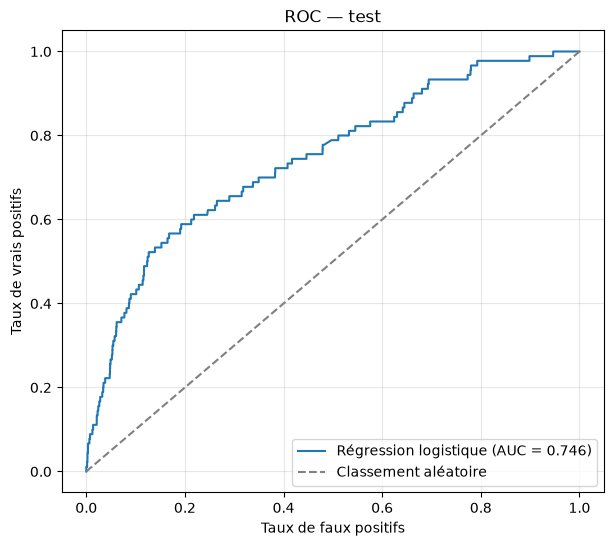

In [166]:
fpr_test, tpr_test, _ = roc_curve(y_test, proba_test)
auc_test = roc_auc_score(y_test, proba_test)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_test, tpr_test, label=f"Régression logistique (AUC = {auc_test:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Classement aléatoire")
ax.set(xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs", title="ROC — test")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.show()

## 15. Modèle concurrent : forêt aléatoire

La régression logistique reste le modèle de référence interprétable. Une forêt aléatoire est ajustée comme modèle concurrent sur les mêmes variables discrétisées et la même séparation train/test. Elle peut signaler une relation non linéaire ou des interactions, mais n'est pas retenue automatiquement comme scorecard réglementaire.

La comparaison utilise les mêmes métriques et le même test. Les hyperparamètres de la forêt ne sont pas optimisés sur ce test ; une recherche de paramètres exigerait une validation croisée interne au train, **par groupes de clients** (`GroupKFold` sur `gdt`) pour ne pas répéter la fuite évoquée en section 2.

In [ ]:
modele_concurrent = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=max(2, int(0.01 * len(y_train))),
    random_state=SEED,
    n_jobs=-1,
)
modele_concurrent.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",624
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the tot

In [ ]:
proba_rf_test = modele_concurrent.predict_proba(X_test)[:, 1]
comparaison_test = pl.DataFrame([
    evaluer_ordonnancement(y_test, proba_test, "Logistique"),
    evaluer_ordonnancement(y_test, proba_rf_test, "Forêt aléatoire"),
])
print(comparaison_test)

shape: (2, 6)
┌─────────────────┬───────┬─────────────┬──────────┬──────────┬──────────┐
│ echantillon     ┆ n     ┆ taux_defaut ┆ AUC      ┆ Gini     ┆ KS       │
│ ---             ┆ ---   ┆ ---         ┆ ---      ┆ ---      ┆ ---      │
│ str             ┆ i64   ┆ f64         ┆ f64      ┆ f64      ┆ f64      │
╞═════════════════╪═══════╪═════════════╪══════════╪══════════╪══════════╡
│ Logistique      ┆ 15639 ┆ 0.005755    ┆ 0.793388 ┆ 0.586777 ┆ 0.505943 │
│ Forêt aléatoire ┆ 15639 ┆ 0.005755    ┆ 0.826616 ┆ 0.653232 ┆ 0.517232 │
└─────────────────┴───────┴─────────────┴──────────┴──────────┴──────────┘


## 16. Conclusion et limites

1. Vérifier convergence, signes/cohérences des coefficients, effectifs par classe, tests globaux et parcimonie avant de retenir une spécification.
2. Justifier chaque variable conservée ou écartée au-delà du seul seuil d'IV ; examiner redondance et stabilité temporelle des classes.
3. Comparer logistique et modèle concurrent sur les mêmes métriques, sans choisir les paramètres à partir du test.
4. La ROC/AUC, le Gini et le KS évaluent la **risk differentiation**. Ils ne calibrent pas une PD : fréquence observée, LRA, PIT/TTC et MoC relèvent de la **risk quantification**.
5. La séparation aléatoire par client n'est pas une validation temporelle. Les dates sont disponibles (`datdelhis`) : prévoir un Out-of-Time.
6. Les variables qualitatives brutes ne sont pas intégrées ici. Leur regroupement, le traitement des modalités rares et l'encodage doivent être définis sans fuite d'information.
7. Plusieurs lignes par client : les p-values non robustes (rapport de vraisemblance, corrélations) sont indicatives ; utiliser les tests et intervalles par grappes.

### Points à documenter dans le rapport

- Justification de la cible, de l'unité d'observation (client × date) et de l'horizon de défaut.
- Traitement des clients multi-dates : découpage par client, erreurs standard par grappes.
- Justification des seuils de découpage, du minimum d'effectif et des bins retenus.
- Contrôle de monotonie/stabilité des taux de défaut, et regroupement expert si nécessaire.
- Résultats sur train, test et idéalement Out-of-Time ; aucune décision basée sur une seule métrique.